#### Autores:
- Iker Alcaide Velasco, 100498961
- Alejandra Cardó González, 100499061

# 1. EDA simplificado

Imports iniciales:

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

Definimos SEED para aleatoriedad, haciendo que los resultados sean replicables, utilizando el NIA de Alejandra:

In [106]:
SEED = 100499061

Abrimos el archivo de datos `bank_61.pkl`, siendo 61 el final de ambos NIAs

In [107]:
with open("bank_61.pkl", "rb") as f:
    df = pickle.load(f)

/tmp/ipykernel_853/276511050.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  df = pickle.load(f)


## 1.1. Visión general del dataset

Con la función `info()` vemos información básica del dataset que usaremos para entrenar y evaluar el modelo:

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11000 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11000 non-null  int64 
 1   job        10764 non-null  object
 2   marital    10871 non-null  object
 3   education  11000 non-null  object
 4   default    11000 non-null  object
 5   balance    11000 non-null  int64 
 6   housing    11000 non-null  object
 7   loan       11000 non-null  object
 8   contact    11000 non-null  object
 9   day        11000 non-null  int64 
 10  month      11000 non-null  object
 11  duration   11000 non-null  int64 
 12  campaign   11000 non-null  int64 
 13  pdays      11000 non-null  int64 
 14  previous   11000 non-null  int64 
 15  poutcome   11000 non-null  object
 16  deposit    11000 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.5+ MB


El dataset contiene 11.000 instancias.

Hay 16 variables feature o atributos:
- **7 numéricas** (int64): `age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`.
- **9 categóricas** (object): `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`.

La variable resultado o target es `deposit`, siendo categórica. Por tanto estamos ante un **problema de clasificación**.

### 1.1.1. Estadísticas descriptivas de variable resultado `deposit`

Como hemos visto, la variable resultado es categórica, pero debemos saber si estamos en un problema de clasificación binaria o multiclase:

In [109]:
df["deposit"].value_counts()

deposit
no     5780
yes    5220
Name: count, dtype: int64

In [110]:
df["deposit"].value_counts(normalize=True).mul(100).round(2)

deposit
no     52.55
yes    47.45
Name: proportion, dtype: float64

Solo hay dos valores posibles para `deposit`:
- **no**: 5760 intancias (52.55%). Instancias de clientes que no contratan.
- **yes**: 5220 instacias (47.45%). Instancia de clientes que sí contratan.

Por tanto estamos ante un **problema de clasificación binaria**, al haber solo dos clases posibles para las instancias.

Podemos visualizar el balance de clases:

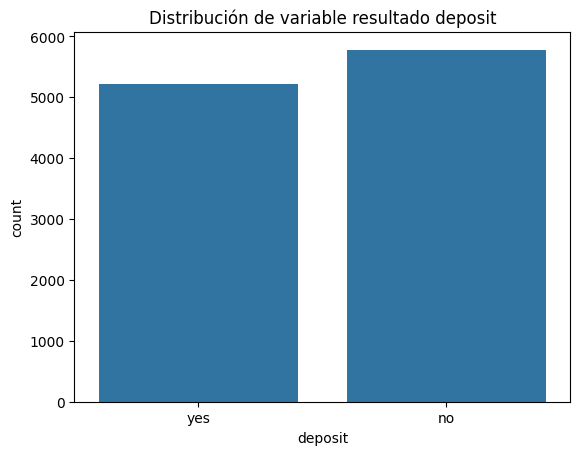

In [111]:
sns.countplot(data=df, x="deposit")
plt.title("Distribución de variable resultado deposit")
plt.show()

El dataset esta bastante balanceado, por lo que no sería necesario realizar técnicas de resampling como SMOTE. Aun así, al no ser perfectamente balanceado, habiendo más instancias de *no* que de *yes*, deberiamos ser cautos y utilizar métricas que tengan esto en cuenta, como **f1 score**.

### 1.1.2. Estadísticas descriptivas de variables numéricas

Utilizamos la función `describe()` para obtener información que nos haga comprender mejor los atributos numéricos:

In [112]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.00000,11000.000000,11000.000000
mean,41.252727,1529.139273,15.660818,372.524909,2.50800,51.308636,0.828000
std,11.940474,3217.396248,8.417970,347.515713,2.72221,108.782842,2.282936
min,18.000000,-6847.000000,1.000000,2.000000,1.00000,-1.000000,0.000000
25%,32.000000,122.750000,8.000000,138.000000,1.00000,-1.000000,0.000000
50%,39.000000,549.500000,15.000000,255.000000,2.00000,-1.000000,0.000000
75%,49.000000,1711.000000,22.000000,498.000000,3.00000,20.250000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.00000,854.000000,58.000000


Observaciones:
- **`age`**: La edad del cliente. Está en un rango de 18 a 95 años, media ~41. Distribución razonable sin valores extremos llamativos.

- **`balance`**: Balance anual medio. Presenta valores negativos (mínimo -6847) y un máximo muy alto (81204), 
  con una std de 3217 muy superior a la mediana (549). Hay outliers claros en la parte alta.

- **`duration`**: Duración en segundos del último contacto (asumimos dentro de la campaña). Media de 372s pero máximo de 3881s (~65 min). También con outliers. Esta variable solo se conoce después de realizar un contacto al menos.

- **`day`**: Día del mes en que fue el contacto. Parece haber una distribución uniforme a priori, teniendo una media y mediana de ~15.

- **`campaign`**: Número de contactos durande la campaña para ese cliente. La mayoría de clientes fueron contactados pocas veces (mediana=2), 
  pero el máximo es 63, lo que sugiere outliers. Lógicamente, el mínimo en 1, porque sino no estarían registrados.

- **`pdays`**: Días desde el último contacto en la campaña anterior. La mediana es -1, implicando que más de la mitad de los clientes nunca fueron contactado en esa campaña anterior.
  Lo trateremos en detalle en la sección dedicada a esta variable.

- **`previous`**: Número de veces que ha sido el cliente contactado antes de esta campaña. La mediana es 0, por tanto, la mayoría de clientes no había sido contactado antes de la campaña.

Creamos un pairplot que muestre las distribuciones individuales (diagonal) y las relaciones entre pares de atributos, coloreadas su clasificación para `deposit` (azul = yes, naranja = no)

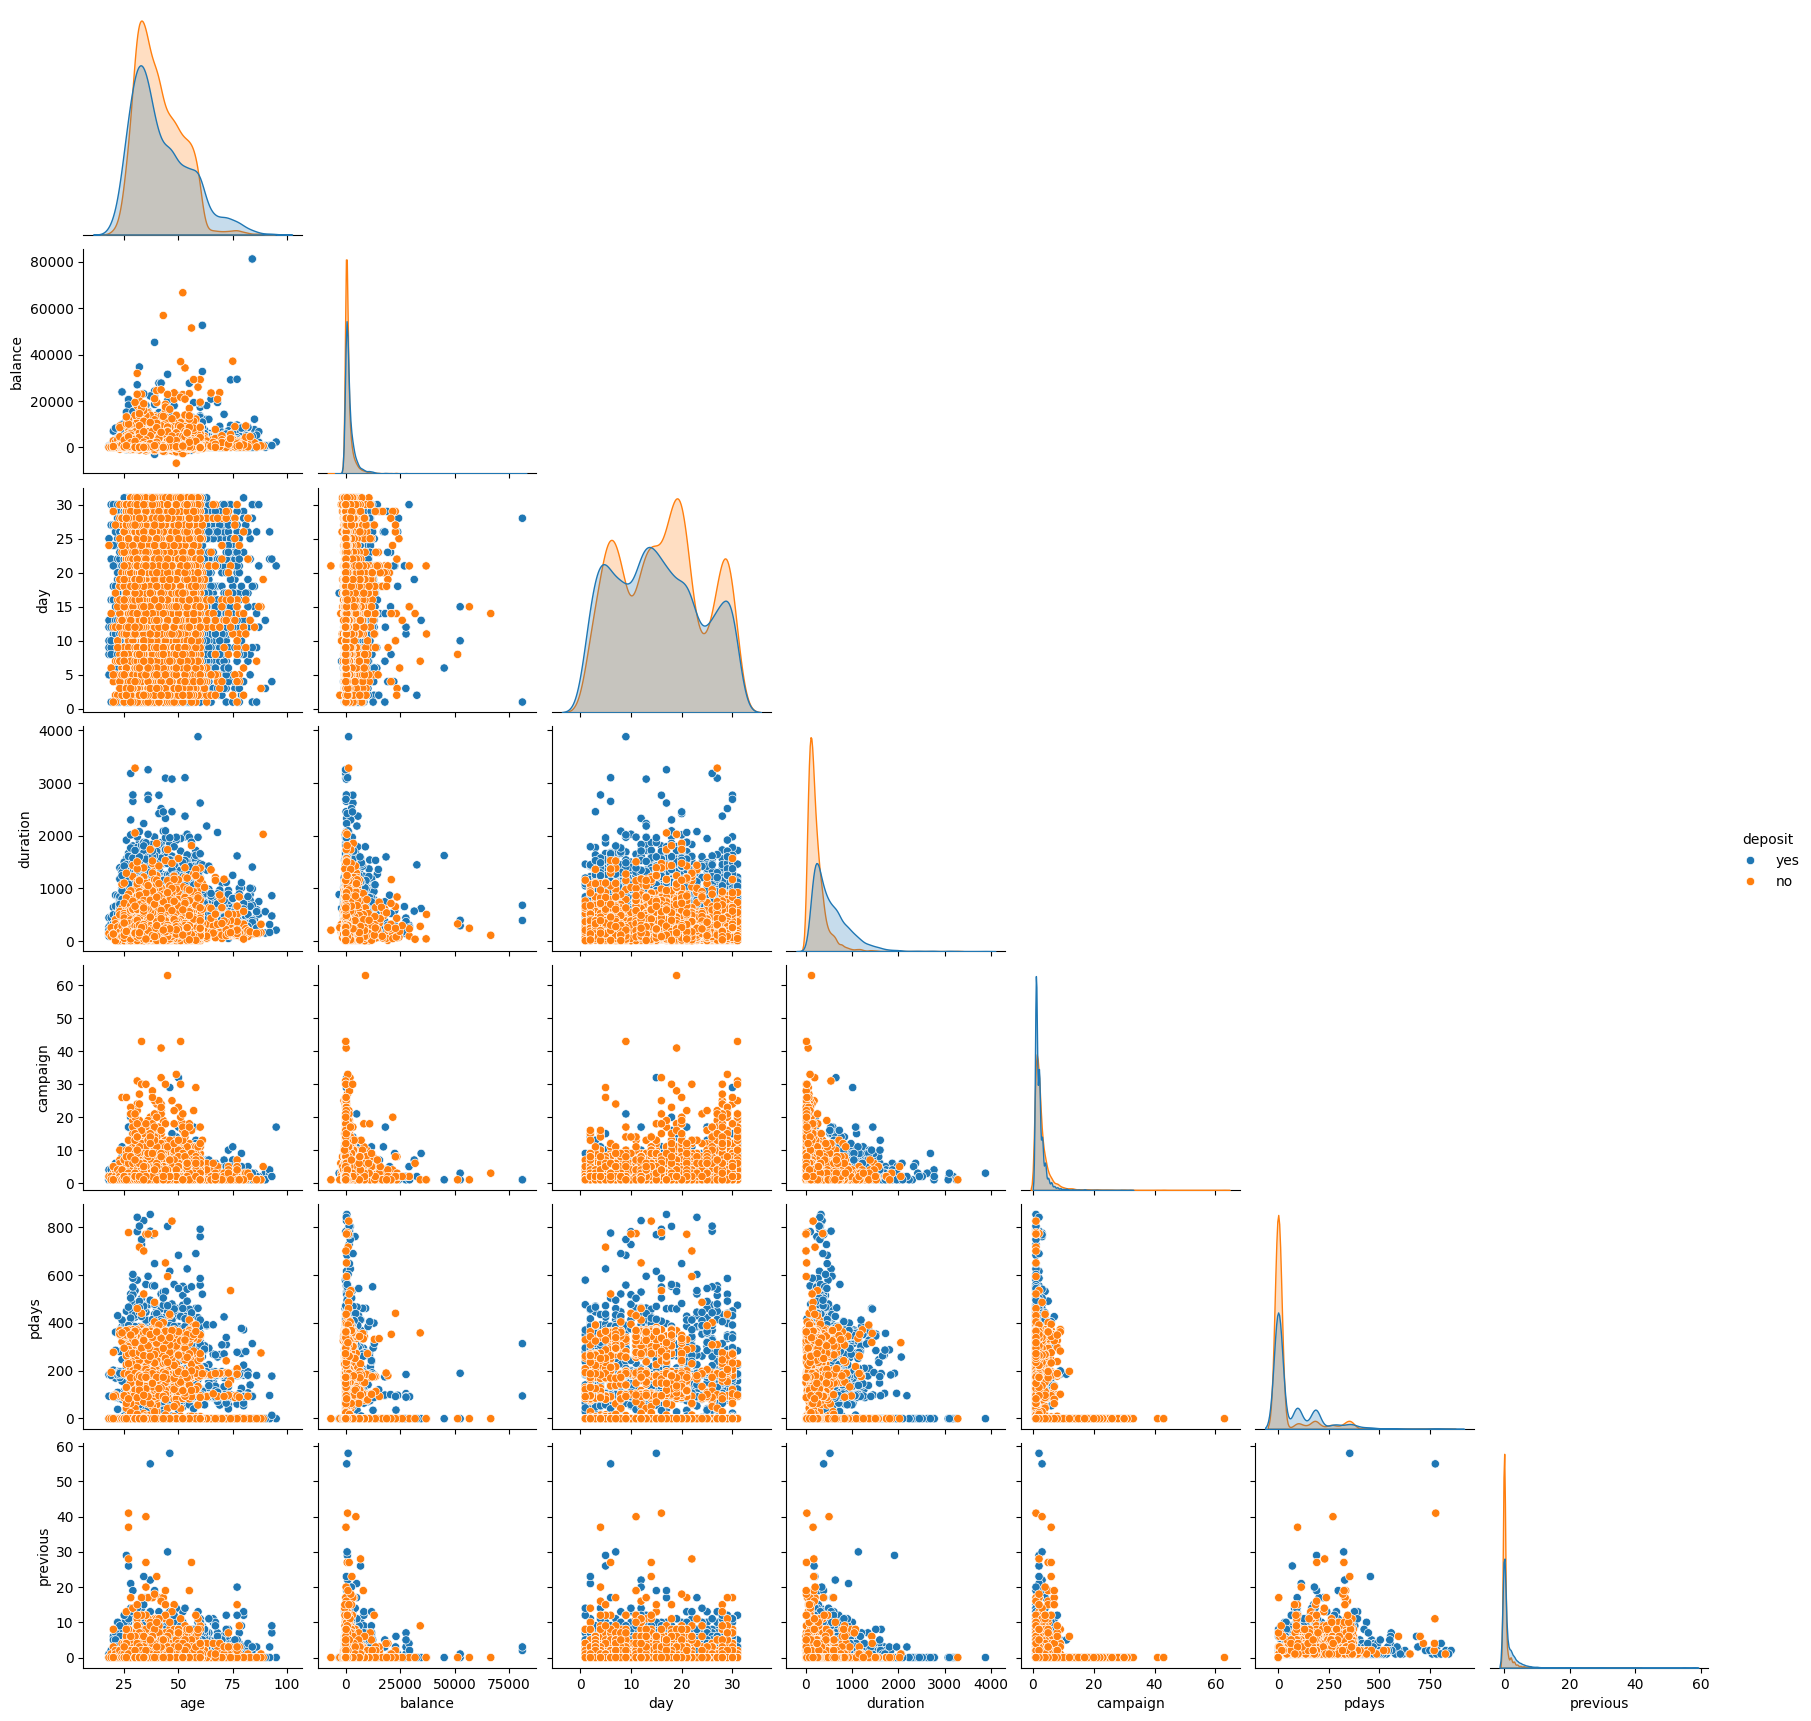

In [113]:
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

sns.pairplot(
    df[num_cols + ["deposit"]],
    hue="deposit",
    corner = True,
    diag_kind="kde"
)
plt.show()

 - **`age`**: La distribución KDE muestra que los clientes que *yes* domina a *no* para edades menores de 25 (ligeramente) y mayores de 60 (más acusado), dominando *no* para edades intermedias.

- **`balance`**: Distribución muy sesgada con outliers extremos. 
  Las clases se solapan casi completamente, por lo que su poder discriminativo es limitado. 
  Justifica el uso de **RobustScaler** para este tipo de variables.

- **`day`**: Su distribución es bastante uniforme entre clases y no muestra correlación relevante con ninguna 
  otra variable. Aun así, parece haber una ligera concentración de *yes* hacia el principio del mes (valores bajos de `day`), aunque su aporte predictivo es limitado.

- **`duration`**: Parece ser la variable numérica con **mayor poder discriminativo** ya que la KDE diagonal muestra una separación clara entre clases. Los clientes que contrataron el depósito (*yes*) tienden a tener duraciones de llamada significativamente mayores.

- **`campaign`**: Se ve claramente una gran concentración de instancias para valores bajos (contactados pocas vece durante la camapaña) pero outliers extremos (muchisimos contactos), aunque no parece que afecte mucho a la variable resutado.

- **`pdays`**: Excluyendo el pico en -1 (que sabemos que es el valor de la mayoría de instancias), parece haber una distribución extraña para valores mallores con varios picos locales de frecuencia alrededor de los 90 y 180 días. Indagaremos más en esto en la sección específica de `pdays`.

- **`previous`**: Muy concentrada en 0, con muy poca separabilidad entre las clases.

Algo que podemos extraer también de estas gráficas es que las variables numéricas presentan solapamiento entre clases, indicando que el problema **no es linealmente separable**. Esto sugiere que métodos no lineales (arboles, SVM con kernel RBF o Gaussiano) podrían rendir mejor que modelos lineales simples.

Además, la presencia de outliers en `balance` o `duration` refuerza la necesidad de utilizar escalado robusto.

### 1.1.3. Estadístics descriptivas de variables catgóricas

In [114]:
df.describe(include="object")

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,10764,10871,11000,11000,11000,11000,11000,11000,11000,11000
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2464,6181,5393,10833,5801,9569,7922,2780,8205,5780


Observaciones:
- **`job`**: Trabajo del cliente. Hay 12 categorías únicas, la más frecuente es *management* (2464 casos). Tiene **missing values** y **alta cardinalidad**, que trataremos más adelante en mayor profundidad.

- **`marital`**: Estado civil del cliente. Solo hay 3 categorías, estando dominada por *married* (~56% de los casos).Pero tiene **missing values**.
- **`education`**: El nivel educativo del cliente. Hay 4 niveles, el más frecuente es *secondary*.

- **`contact`**: Tipo de contacto del cliente. Hay 3 tipos, el más común es *cellular* (7922 casos).

- **`month`**: Mes de último contacto con el cliente. Tiene 12 valores únicos, siendo el mes más frecuente *may*. Por tanto, tiene **alta cardinalidad**.

- **`poutcome`**: Resultado de campañas de marketing anteriores. 4 categorías, pero *unknown* domina claramente (8205/11000 ≈ 75%). 
  Esto está muy relacionado con `pdays`: la mayoría de clientes no tenía campaña previa.

- **Atributos binarios** (*yes*, *no*): **`housing`** (tiene o no casa), **`loan`** (tiene o no un préstamo) y **`default`** (ha entrado o no en default). Esta última está muy desbalanceada, habiendo 10833/11000 clientes que no han entrado en default.


Podemos crear plots para comparar y entender mejor cómo afectan los diferentes valores de los atributos categóricos a la variable resultado.

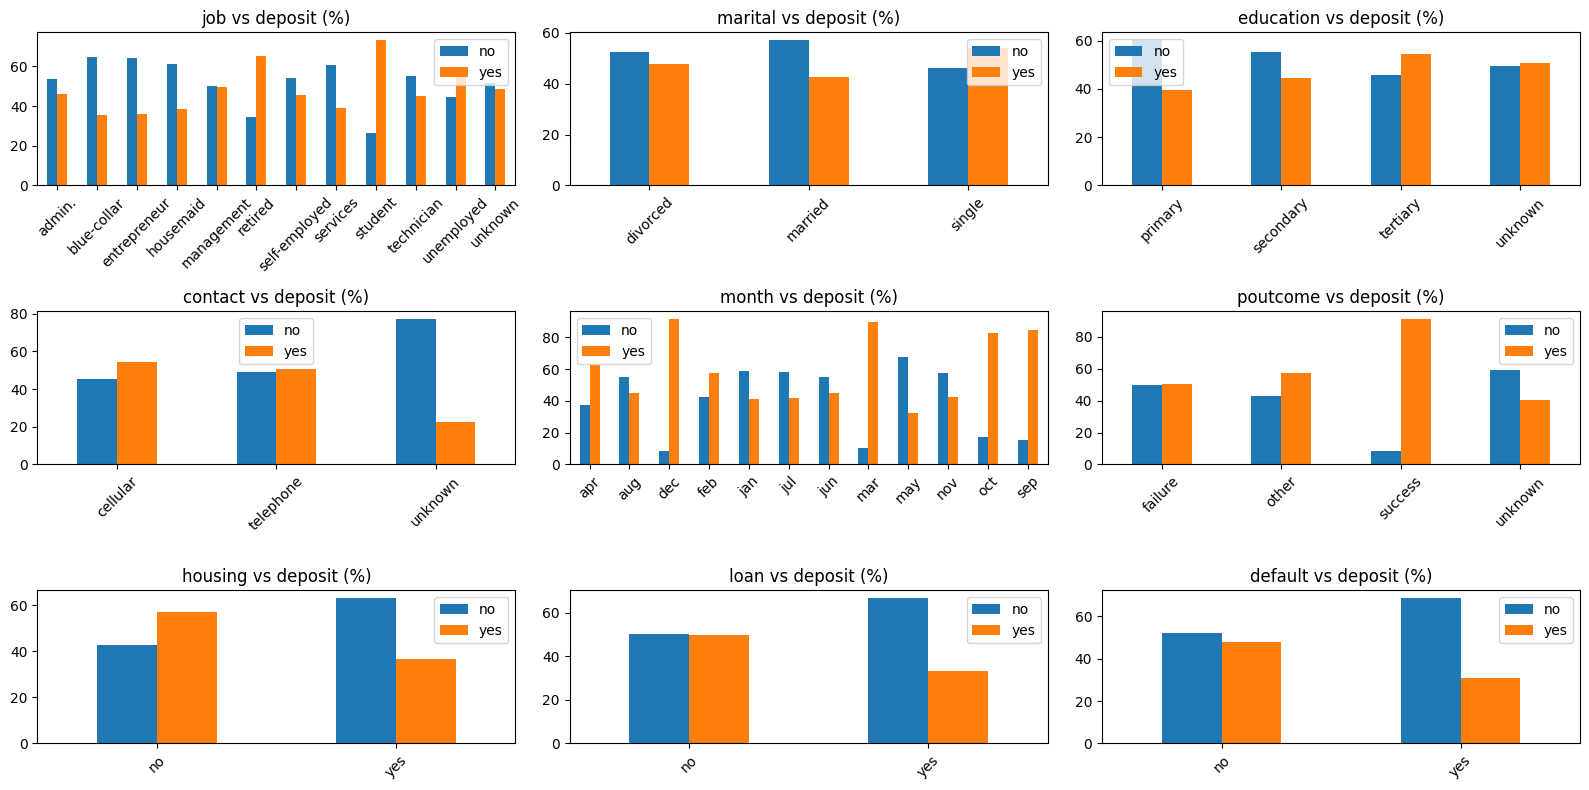

In [115]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8))

cats = ["job", "marital","education", "contact", "month", "poutcome", "housing", "loan", "default"]
for ax, col in zip(axes.flatten(), cats):
    ct = pd.crosstab(df[col], df["deposit"], normalize="index") * 100
    ct.plot.bar(ax=ax, stacked=False)
    ax.set_title(f"{col} vs deposit (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(["no", "yes"])

plt.tight_layout()
plt.show()

- **`job`**: *student* y *retired* tienen las tasas de conversión más altas.

- **`marital`**: se ve que el único grupo en el que gana el *yes* es para los solteros (*single*).
- **`education`**: los clientes con mayor nivel educativo (*tertiary*) son más propensos a contratar el deposito, aunque no hay casi diferencias para los que no sabemos su nivel educativo (*unknown*).
- **`contact`**: tanto a través de llamadas al celular como al teléfono se consigue más contratación del deposito. Para los *unknown* domina el *no*.
- **`month`**: hay meses con tasas muy distintas (marzo, septiembre y octubre destacan muy positivamente).
- **`poutcome`**: los clientes con resultado *success* en la campaña anterior tienen una tasa de conversión altísima (>90%). Será una variable muy relevante.
- **`housing`**: los que no tienen casa son mas propensos a contratar el deposito.
-**`loan`**: la proporción de los que contratan entre los que no tienen un préstamo es balanceada, pero los que sí tienen un préstamo en general no contratan el depósito.
- **`deault`**: pasa parecido que con `loan`. Los que están en default no suelen contratar el depósito, mientras que no hay diferencias acusadas entre los que no estan en default.

Parece que las variables categóricas son, en general, más discriminantes que las numéricas.

Podemos afirmar que no hay **ninguna columna constante**: ninguna variable tiene unicamente un valor/clase en todas sus instancias.

También podemos afirmar que no hay **ninguna columna ID**: ningún atributo tiene valores diferentes para cada instancia que identifiquen a cada una.

### 1.1.4. Valores faltantes (Missing values)

In [116]:
df.isnull().sum()

age            0
job          236
marital      129
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
deposit        0
dtype: int64

Como hemos identificado previamente, unicamente 2 variables presentan valores nulos (ambas categóricas):
- **`job`**: 236 nulos (~2.1% del total)
- **`marital`**: 129 nulos (~1.2% del total)

Son porcentajes bajos, por lo que no es necesario descartar estas variables, pero tampoco queremos tener que eliminar estas instancias perdiendo información.

Se deberá realizar un preprocesado de imputación dentro de la pipeline (después de haber dividido el dataset en el conjunto de entrenamiento y el conjunto de test). Habrá varias opciones que discutiremos en el apartado en el que imputemos estos valores.

### 1.1.5. Cardinalidad de variables categóricas

In [117]:
df.select_dtypes("object").nunique().sort_values(ascending=False)

job          12
month        12
poutcome      4
education     4
marital       3
contact       3
loan          2
housing       2
default       2
deposit       2
dtype: int64

Como hemos comprobado previamente unicamente `job` y `month` superan el umbral de los 10 valores únicos. 

Al tener un dataset muy grande, y ser `job` no ordinal (no podemos asumir que un trabajo es mejor que otro) tiene sentido seguir usar One-Hot Encoding, aunque no es lo ideal para **arboles de decisión**, pero no destrozará el rendimiento.

Para `month` lo ideal es hacer una **codificación cíclica**, haciendo que KNN, lineales y SVM entiendan que enero y diciembre en verdad son próximos. Esta se hará, al igual que el One-Hot Encoding del resto de variables categóricas **en pipeline y tras dividir train y test**, ya que, aunque no tiene riesgo de *data leakage*, la práctica especifica que es preferible realizar todo el preprocesado de esta manera, consiguiendo adaptar los datasets reales automáticamente.

## 1.2. Análisis de `pdays`

### 1.2.1. Análisis general de `pdays`

`pdays` representa el número de días desde que el cliente fue contactado en la campaña anterior, donde *-1* significa **que nunca fue contactado**.

Es por esto por lo que se pide que se analice `pdays` en particular.

Podemos analizar la variable en mayor profundidad `pdays` con **describe()** y **value_counts()**:

In [118]:
df["pdays"].describe()

count    11000.000000
mean        51.308636
std        108.782842
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         20.250000
max        854.000000
Name: pdays, dtype: float64

In [119]:
df["pdays"].value_counts().head(10)

pdays
-1      8203
 92      105
 182      88
 91       82
 181      79
 183      73
 184      51
 94       42
 93       40
 95       37
Name: count, dtype: int64

Podemos además calcular la proporción de *-1*:

In [120]:
print("Proporción de -1 en pdays: ", (df["pdays"] == -1).sum() / len(df))

Proporción de -1 en pdays:  0.7457272727272727


Como el percentil 25 y 50 (mediana) están en -1, lo que indica, como ya sabíamos, que la gran **mayoría de clientes nunca tuvo contacto previo**. En concreto, el **74.6% de las instancias** tiene el valor -1.

Esto es un problema si tratamos `pdays` como variable numérica ordinaria, ya que el -1 no representa "muy pocos días" sino directamente "ausencia de contacto". Es decir, un escalador lo interpretaría erróneamente como un valor bajo, distorsionando el aprendizaje.

Más allá de esto, podemos analizar los valores de `pdays` excluyendo los *-1*, es decir solo con los clientes contactados previamente:

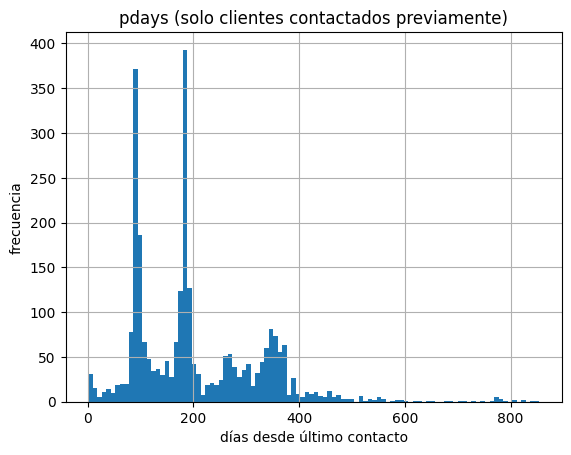

In [121]:
df[df["pdays"] != -1]["pdays"].hist(bins=100)
plt.title("pdays (solo clientes contactados previamente)")
plt.xlabel("días desde último contacto")
plt.ylabel("frecuencia")
plt.show()

Como habiamos intuido a través de los pairplot en el análisis de **estadísticas descriptivas de variables numéricas**, hay mayores frecuencias o picos en la distribución alrededor de los 90 y 180 días (3 y 6 meses, respectivamente), pudiendo ser posible que sea común contactar a los clientes cada 3 o 6 meses, o que simplemente hubiera grandes campañas justo en esos periodos.

A su vez, también hay picos menores alrededor de 270 y 365 (1 año), siguiendo el patrón de 90 días.

### 1.2.2. Estrategias de preproceso posible

Evaluaremos una cuantas alternativas de preproceso posible y escogeremos la mejor para llevarla a cabo. Está justificado realizar este preproceso en esta sección porque **no genera data leakage**, al no calcular medias, varianzas o mirar la variable objetivo `deposit`.

#### 1.2.2.1. Variable binaria `wasContacted`

Consiste en sustituir `pdays` por una variable binaria que toma valores de 1 si pdays != -1 y 0 si pdays = -1. Es decir, reducimos la información explícitamente a si hubo contacto previo o no.

In [122]:
df["wasContacted"] = (df["pdays"] != -1).astype(int)
df["wasContacted"].value_counts()

wasContacted
0    8203
1    2797
Name: count, dtype: int64

Podemos visualizar en una gráfica como quedaría la distribución de esta variable binaria:

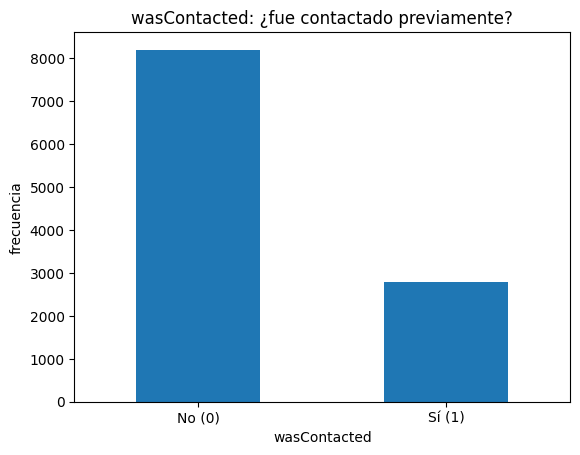

In [123]:
df["wasContacted"].value_counts().plot.bar()
plt.title("wasContacted: ¿fue contactado previamente?")
plt.xticks([0, 1], ["No (0)", "Sí (1)"], rotation=0)
plt.ylabel("frecuencia")
plt.show()

Esta es una solución simple al problema, pero, como hemos visto, hay información interesante sobre la temporalidad de los si contactados, que perderíamos de esta manera.

Podríamos pensar que para solventar esto podemos no eliminar `pdays` y poner sus valores *-1* a *NA*, pero esto haría que al realizar la imputación se creara mucho ruido e instancias no realistas. No es una buena solución.

#### 1.2.2.2. Variable continua `continuousPdays`

Esta solución es para crear una variable que pueda sustituir a `pdays` por una variable también continua pero en la que los no contactados tengan asociado un valor muy alto (999).

In [124]:
df["continuousPdays"] = df["pdays"].map(
    lambda x: 999 if x == -1 else x
)

Podemos visualizar como quedaría la distribución:

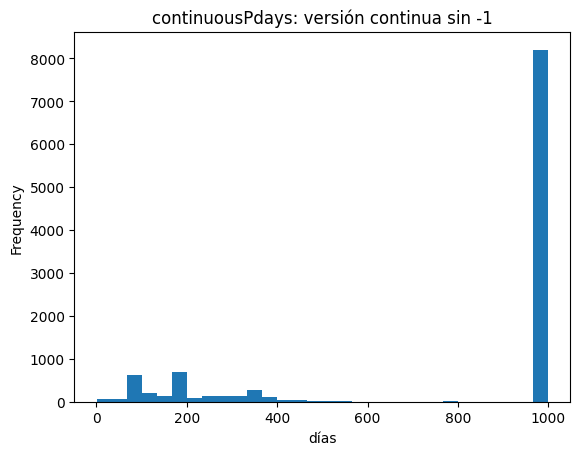

In [125]:
df["continuousPdays"].plot.hist(bins=30)
plt.title("continuousPdays: versión continua sin -1")
plt.xlabel("días")
plt.show()

Esta opción tiene sentido intuitivo: a más días, más tiempo hace y peor campaña actual, haciendo que no contactado sea igual a el caso más alejado. Sin embargo, estamos asumiendo que "no contactado" es equivalente a "contactado hace muchísimo tiempo", lo cual es una simplificación que, además, puede ser dañina para algunos algoritmos.

#### 1.2.2.3. Variable ordinal discreta `pdaysRange`

Esta opción agrupa los días en rangos significativos manteniendo el orden temporal y consiguiendo además tener una clase con los no contactados:

In [126]:
def bin_pdays(x):
    if x == -1: return 'nunca_contactado'
    if x <= 90: return '1_trimeste'
    elif x <= 180: return '2_trimestre'
    elif x <= 270: return '3_trimestre'
    elif x <= 365: return '4_trimestre'
    else: return 'mas_1_ano'
df["pdaysRange"] = df["pdays"].map(bin_pdays)
df["pdaysRange"].value_counts().sort_index()

pdaysRange
1_trimeste           326
2_trimestre          936
3_trimestre          769
4_trimestre          515
mas_1_ano            251
nunca_contactado    8203
Name: count, dtype: int64

> ⚠️ **Decisión de rangos elegidos**: asumimos estos rangos como una **Regla de Negocio** (trimestres naturales en banca), y no como cortes empíricos extraídos de los datos. 

Podemos visualizar la distribución de las clases:

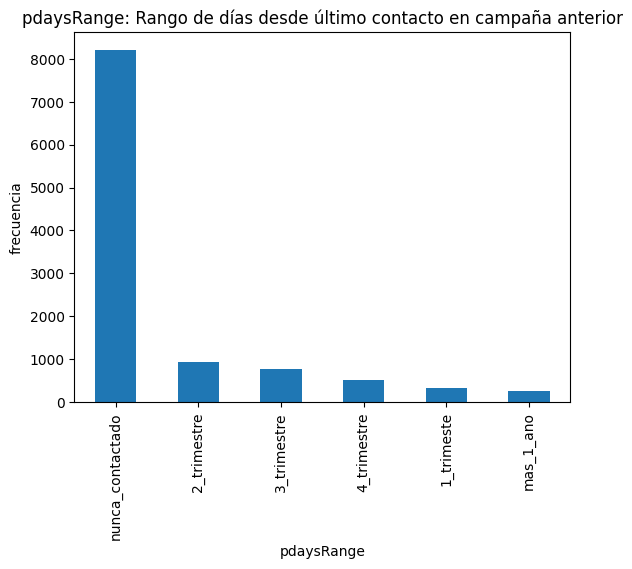

In [127]:
df["pdaysRange"].value_counts().plot.bar()
plt.title("pdaysRange: Rango de días desde último contacto en campaña anterior")
plt.ylabel("frecuencia")
plt.show()

Esta es la opción más adecuada para el preproceso de `pdays`, pues aisla *-1* en su propia categoría, manteniendo información temporal de cuándo se contactó a los que sí fueron contactados.

Al aplicarle One-Hot Encoding posteriormente, todos los modelos (KNN, SVM, Lineales y Árboles) la digerirán perfectamente.

### 1.2.3. Preproceso decidido

La mejor opción será una opción de preprocesado basada en la última opción explorada, **pdaysRange**, pero no directamente creando esa columna en este apartado y eliminando `pdays`:

Tecnicamente no incurriríamos en **data leakage** si crearamos directametne `pdaysRange` antes de hacer la división train/test, debido a que no se está aprendiendo ningún parámetro de los datos. Aun así, la práctica especifica que siempre que sea posible se realice el preprocesado en **pipelines**, garantizando que el proceso se aplique automaticamente sobre **cualquier dataset nuevo** al predecir, y no tener que realizar preprocesado "a mano" antes de aplicar el modelo.

Por tanto la solución será en una pipeline transformar `pdays` en una variable categórica que se comporte como `pdaysRange` en el momento de realizar el preproceso.

Es por esto que limpiamos las columnas de exploración y mantenemos `pdays` en esta sección, sujeto a un futuro preproceso en la sección correspondiente:

In [128]:
df.drop(columns=["wasContacted", "continuousPdays", "pdaysRange"], inplace=True)

# 2. Estrategia de Evaluación

## 2.1. Métrica de evaluación

Como comentabamos en la fase de EDA, el dataset esta bastante balanceado en base a la variable objetivo (52.5% / 47.5%). Aun así, es conveniente usar como métrica princial **F1-score**, siendo más informativo que accuracy en clasificación binaria al combinar:

- **recall**: proporción de instancias de *clase positiva* (la minoritaria, en este caso *yes*) clasificadas correctamente.

- **precisión**: proporción de instancias clasificadas como clase positiva que verdaderamente lo son.

Existe un *trade-off* entre estas, pero F1 las combina en una única métrica (es la media armónica de ambas), para así poder maximizarlas.

## 2.2. Evaluación outer: Holdout train/test

Para estimar el rendimiento futuro del modelo final se usa **Holdout**:

- **Train (2/3)**: usado para entrenar y comparar modelos (evaluación inner).

- **Test (1/3)**: reservado exclusivamente para evaluar el modelo final al final de la práctica. No se usará para pasos intermedios.

In [129]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["deposit"])
y = df["deposit"]

Usamos el parámetro `stratify = y` para estratificar la muestra y, de esta manera, asegurarnos que el balance se mantiene en ambas particiones.

In [130]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    random_state=SEED,
    stratify=y
)

print(f"Train: {X_train.shape[0]} instancias ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Test:  {X_test.shape[0]} instancias ({X_test.shape[0]/len(df)*100:.1f}%)")

Train: 7333 instancias (66.7%)
Test:  3667 instancias (33.3%)


Podemos comprobar como los balances son practicamente los mismos en ambas particiones:

In [131]:
print(f"\nBalance en train:\n{y_train.value_counts(normalize=True).mul(100).round(2)}")
print(f"\nBalance en test:\n{y_test.value_counts(normalize=True).mul(100).round(2)}")


Balance en train:
deposit
no     52.54
yes    47.46
Name: proportion, dtype: float64

Balance en test:
deposit
no     52.55
yes    47.45
Name: proportion, dtype: float64


## 2.3. Evaluación inner: Validación cruzada

Para comparar modelos y optimizar hiperparámetros (HPO) a lo largo de la práctica, evitando *Data Leakage* y *Overfitting*, se usará **k-fold corss-validation con k = 3** sobre el conjunto de train:

- Divide en 3 folds el conjunto de entrenamienta, entranando 2 folds y validando con el otro. la métrica final es la media de los 3 folds.

- Es más fiable que un único split de validación porque reduce la varianza de la estimación.

- Se usará integrado en `GridSearchCV` (para probar todas las combinaciones posibles) y `cross_val_score` de scikit-learn, siempre con `random_state=SEED` para reproducibilidad.

In [132]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

Se usa `StratifiedKFold` en lugar de `KFold` estándar para mantener el balance de clases en cada fold, al igual que hicimos en el Holdout.

**Resumen**:
 Nivel | Método | Datos usados | Cuándo |
|---|---|---|---|
| **Outer** | Holdout 2/3 - 1/3 | Train + Test | Solo al final, modelo final |
| **Inner** | 3-fold CV estratificado | Solo Train | HPO y comparación de modelos |
> ⚠️ El conjunto de **test no se tocará hasta el apartado final** de la 
> práctica, cuando se evalúe el modelo definitivo elegido.

# 3. Métodos Básicos: KNN y Trees

In [133]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn import tree
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance


Importamos el F1 score y lo convertimos en nuestra métrica:

In [134]:
from sklearn.metrics import make_scorer, f1_score
f1 = make_scorer(f1_score, pos_label="yes")

## 3.1. Preprocesado

Definimos las columnas según su tipo, no incluyendo `month` ni `pdays` para procesarlos con transformadores personalizados

In [135]:
num_atrib = ["age", "balance", "day", "duration", "campaign", "previous"]

cat_atrib = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]

### 3.1.1. Preprocesador categórico común a todos los modelos 

Todo el preprocesado se realiza **dentro de las pipelines** para evitar 
data leakage: los parámetros aprendidos (moda, mediana, escalado) se 
calculan únicamente sobre el fold de train en cada iteración del CV.

Para codificar las columnas categóricas se utiliza **OneHotEncoder**, que es el estándar. Creará una columna binarias para cada valor de las diferentes variables categoricas.

Para **imputar missing values**, los unicos presentes son en `job` (236) y `marital` (129), 
ambas categóricas. Las variables numéricas no tienen ningún valor faltante. Tras varios métodos diferentes probados sobre todos los modelos (esto es de lo último que hemos decidido) hemos valorado principalmente 3 alternativas:
- Moda del atributo: F1 score pésimo para algunos algoritmos como árboles.
- Multivariante: muy complejo y no vale la pena para tan pocos valores.
- Crear valor **"unknown"** o utilizar ese valor si ya existe (como en `job`). F1 score bueno.
- Crear valor **"missing"**, que no existe en ninguna variable. F1 score ligeramente mejor.

Al final se opta por **"valor missing"**, cosa que se verá que es acertada en la sección **4.1.5. Análisis de Relevancia de Atributos**:

In [136]:
cat_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing", missing_values=None)),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

### 3.1.2. Transformador personalizado para `month`

`month` es transformado con la siguiente función para realizar un **encoding cíclico** en el pipeline, como habíamos discutido en el EDA:

In [137]:
from sklearn.preprocessing import FunctionTransformer

def encode_cyclical_month(X):
    month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                 'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m_series = pd.Series(X.iloc[:, 0]).map(month_map)
    sin_values = np.sin(2 * np.pi * m_series / 12)
    cos_values = np.cos(2 * np.pi * m_series / 12)
    return np.column_stack([sin_values, cos_values])

cyclical_month_transformer = FunctionTransformer(encode_cyclical_month)

### 3.1.3. Transformador personalizado para `pdays`

`pdays` es transformado con la siguiente función para utilizarla como una variable categórica que maneje los *-1* (no contactados previamente) y retener información temporal:

In [138]:
def bin_pdays(X):
    def logic(x):
        if x == -1: return 'nunca_contactado'
        if x <= 90: return '1_trimestre'
        elif x <= 180: return '2_trimestre'
        elif x <= 270: return '3_trimestre'
        elif x <= 365: return '4_trimestre'
        else: return 'mas_1_ano'
    
    # Funciona tanto con DataFrame como con numpy array
    if hasattr(X, 'iloc'):
        values = X.iloc[:, 0]
    else:
        values = X[:, 0]
    
    return pd.DataFrame(pd.Series(values).apply(logic))

pdays_bin_transformer = FunctionTransformer(bin_pdays)

Además, creamos un preprocesador específico para pdays que discretiza y luego realiza OHE. validate = False para evitar problemas con el formato

In [139]:
pdays_preprocessor = Pipeline([
    ("binning", pdays_bin_transformer),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

### 3.1.4. Selección del método de escalado con KNN

KNN basa sus predicciones en distancias euclídeas, por lo que variables 
con rangos muy distintos distorsionarían el cálculo si no se escalan. 
Por ejemplo, `balance` (rango -6847 a 81204) dominaría sobre `age` 
(18 a 95) simplemente por su escala.

Se compararán tres métodos:
- **MinMaxScaler**: escala al rango [0,1]. Muy sensible a outliers.
- **StandardScaler**: estandariza a media=0, std=1. Sensible a outliers, pero funciona bien si la escala suficientemente simétrica.
- **RobustScaler**: usa mediana e IQR. Robusto frente a outliers. Es el más prometedor a priori.

Para elegir el escalador usamos KNN con sus hiperparámetros por 
omisión (k=5) y evaluamos con 3-fold CV sobre train. El objetivo 
aquí es únicamente decidir el escalador, no optimizar k todavía 
(eso se hará en la sección 4.2).

Todo el preprocesamiento se realiza dentro de la pipeline para 
garantizar que no hay data leakage: el escalador aprende sus 
parámetros solo del fold de train en cada iteración del CV.

#### 3.1.4.1. Construcción de pipelines

Construimos una pipeline por escalador. Cada pipeline incluye:
- Imputación (por robustez) y escalado para variables numéricas.
- Imputación y OHE para variables categóricas, utilizando cat_preprocesssor`
- Para el caso específico de `month`, se utilizará su fnción transformadora personalizada.
- De manera similar, para el caso de `pdays`, se ultilizará su preprocesador específico.


- KNN (k =  5 por omisión).

Primera Alternativa: MinMaxScaler

In [140]:
num_minmax = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler", MinMaxScaler())])
preprocessor_minmax = ColumnTransformer([
    ("num", num_minmax, num_atrib),
    ("month_cyc", Pipeline([
        ("cyclic", cyclical_month_transformer),
        ("scaler", MinMaxScaler())
    ]), ["month"]),
    ("pdays_p", pdays_preprocessor, ["pdays"]),
    ("cat", cat_preprocessor, cat_atrib)
])
pipeline_minmax = Pipeline([("preprocessor", preprocessor_minmax),
                             ("knn", KNeighborsClassifier())])

Segunda alternativa: StandardScaler

In [141]:
num_standard = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])

preprocessor_standard = ColumnTransformer([
    ("num", num_standard, num_atrib),
    ("month_cyc", Pipeline([
        ("cyclic", cyclical_month_transformer),
        ("scaler", StandardScaler())
    ]), ["month"]),
    ("pdays_p", pdays_preprocessor, ["pdays"]),
    ("cat", cat_preprocessor, cat_atrib)
])

pipeline_standard = Pipeline([("preprocessor", preprocessor_standard),
                               ("knn", KNeighborsClassifier())])

Tercera alternativa: RobustScaler

In [142]:
num_robust = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler", RobustScaler())])
preprocessor_robust = ColumnTransformer([
    ("num", num_robust, num_atrib),
    ("month_cyc", Pipeline([
        ("cyclic", cyclical_month_transformer),
        ("scaler", RobustScaler())
    ]), ["month"]),
    ("pdays_p", pdays_preprocessor, ["pdays"]),
    ("cat", cat_preprocessor, cat_atrib)
])
pipeline_robust = Pipeline([("preprocessor", preprocessor_robust),
                             ("knn", KNeighborsClassifier())])

#### 3.1.4.2. Evaluación de métodos de escalado

Evaluamos cada pipeline con 3-fold CV sobre train. 

In [143]:
scores_minmax   = cross_val_score(pipeline_minmax,   X_train, y_train, cv=cv, scoring=f1)
scores_standard = cross_val_score(pipeline_standard, X_train, y_train, cv=cv, scoring=f1)
scores_robust   = cross_val_score(pipeline_robust,   X_train, y_train, cv=cv, scoring=f1)

Imprimimos por pantalla los resultados del F1 score y las desviaciones típicas para cada alternativa

In [144]:
print(f"MinMaxScaler:   {scores_minmax.mean():.4f} ± {scores_minmax.std():.4f}")
print(f"StandardScaler: {scores_standard.mean():.4f} ± {scores_standard.std():.4f}")
print(f"RobustScaler:   {scores_robust.mean():.4f} ± {scores_robust.std():.4f}")

MinMaxScaler:   0.6742 ± 0.0061
StandardScaler: 0.7815 ± 0.0063
RobustScaler:   0.7653 ± 0.0072


Podemos visualizarlo con un boxplot:

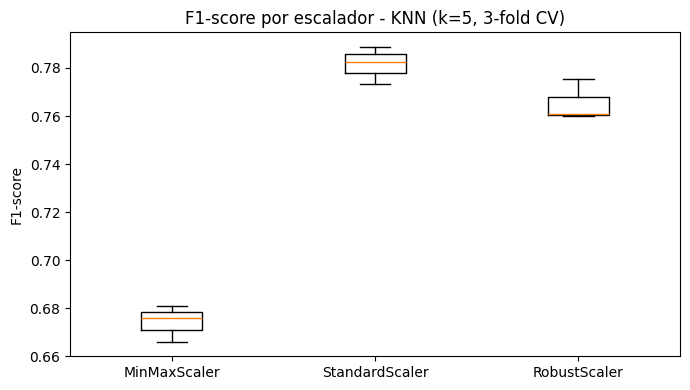

In [145]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([scores_minmax, scores_standard, scores_robust],
           tick_labels=["MinMaxScaler", "StandardScaler", "RobustScaler"])
ax.set_title("F1-score por escalador - KNN (k=5, 3-fold CV)")
ax.set_ylabel("F1-score")
plt.tight_layout()
plt.show()

#### 3.1.4.3. Método de escalado seleccionado

El escalador seleccionado es **StandardScaler** con un F1 score de **0.715**

Aunque el EDA mostró outliers notables en `balance`, `duration` y 
`campaign`, que hacían a RobustScaler el candidato más prometedor, 
los resultados muestran que **StandardScaler obtiene mejor rendimiento** 
en la práctica. 

Esto puede deberse a que, si bien existen outliers, 
la distribución general de las variables numéricas es suficientemente 
simétrica como para que la estandarización (media=0, std=1) produzca 
distancias más útiles para KNN que el escalado robusto.

MinMaxScaler queda muy por detrás. Al comprimir todo al rango [0,1], 
los outliers extremos de `balance` hacen que el resto de valores 
queden comprimidos en un rango muy pequeño, distorsionando las 
distancias entre clientes.

**StandardScaler se usará de aquí en adelante** en todos los modelos 
que requieran escalado.

In [146]:
preprocessor_final = preprocessor_standard

## 3.2. Clasificador Dummy

Antes de evaluar KNN y árboles, establecemos clasificador dummy que no aprende nada de los datos. Cualquier modelo útil debe superarlo claramente.

Usamos `strategy="stratified"`: predice cada clase aleatoriamente 
respetando la distribución real (52.5% *no* / 47.5% *yes*). Es el 
baseline más adecuado cuando la métrica es F1-score.

In [147]:
dummy = DummyClassifier(strategy="stratified", random_state=SEED)
dummy_scores = cross_val_score(dummy, X_train, y_train,
                               cv=cv, scoring=f1)
print(f"Dummy (stratified): {dummy_scores.mean():.4f} ± {dummy_scores.std():.4f}")

Dummy (stratified): 0.4836 ± 0.0084


**¿Por qué no usamos `strategy="most_frequent"` ni accuracy?**

Con `most_frequent` el dummy predice siempre *no*, nunca prediciendo 
la clase positiva (*yes*). Esto daría:
- **Accuracy**: ~52.5% (simplemente acierta por predecir siempre la 
  mayoritaria), aparentando un rendimiento razonable.
- **F1-score**: 0.0 exacto, ya que al no predecir nunca *yes*, tanto 
  la precisión como el recall para esa clase son cero.

Esto ilustra exactamente por qué usamos **F1-score en lugar de accuracy**: 
en este problema nos interesa identificar correctamente los clientes 
que *sí* contratarán el depósito (*yes*), y accuracy no penaliza 
ignorar completamente esa clase si el dataset está suficientemente 
balanceado. El F1-score, al combinar precisión y recall, sí lo penaliza.

Con `strategy="stratified"` el dummy obtiene un F1 bajo pero no cero, 
siendo una referencia mínima más honesta: cualquier modelo que aprenda 
algo real debe superarla con claridad.

## 3.3. K-Nearest Neighbors (KNN)

### 3.3.1. KNN con hiperparámetros por omisión

Evaluamos KNN con k = 5 (valor por omisión), utilizando el estimador selccionado previamente (StandardScaler)

In [148]:
knn_default = Pipeline([
    ("preprocessor", preprocessor_final),
    ("knn", KNeighborsClassifier())
])

También medimos los tiempos que tarda el entrenamiento:

In [149]:
t0 = time.time()
knn_default_scores = cross_val_score(knn_default, X_train, y_train,
                                     cv=cv, scoring=f1)
t_knn_default = time.time() - t0

In [150]:
print(f"KNN (default, k=5): {knn_default_scores.mean():.4f} ± {knn_default_scores.std():.4f} "
      f"| tiempo: {t_knn_default:.2f}s")

KNN (default, k=5): 0.7815 ± 0.0063 | tiempo: 0.20s


KNN con k=5 supera claramente al dummy (0.7815 > 0.4836), confirmando que captura 
información real del problema. Sin embargo, k=5 es un valor arbitrario: 
el HPO determinará el k óptimo para este problema.

### 3.3.2. KNN con HPO

Optimizamos los hiperparámetros más importantes de KNN con **3-fold CV**:
- **`n_neighbors` (k)**: El más importante. Si usamos valores bajos tendremos overfitting, mientras que valores altos darán lugar a underfitting. Al ser un problema de clasificación binaria hay que usar **números impares** para evitar empates.
- **`weights`**: votos uniformes (*uniform*) o ponderados por 
  distancia (*distance*).

In [151]:
param_grid_knn = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 21, 31],
    "knn__weights":     ["uniform", "distance"]
}

knn_pipeline_hpo = Pipeline([
    ("preprocessor", preprocessor_final),
    ("knn", KNeighborsClassifier())
])

> ⚠️ **No probamos las distancias** (euclidean, manhattan, etc.): porque la distancia euclidiana funciona bien para nuestro problema, siendo el estándar. De usar Manhattan, tendríamos diversos problemas con las combinaciones con Manhattan y pesos 'distance'.

> Utilizamos el hiperparámetro por omisión: **euclidean distance**

Lo hacemos mediante **GridSerchCV**, probando todas las combinaciones de hiperparámetros, cosa que es posible porque no son demasiadas:

In [152]:
t0 = time.time()
grid_knn = GridSearchCV(knn_pipeline_hpo, param_grid_knn,
                        cv=cv, scoring=f1, n_jobs=-1)
grid_knn.fit(X_train, y_train)
t_knn_hpo = time.time() - t0

In [153]:
print(f"Mejores hiperparámetros: {grid_knn.best_params_}")
print(f"Mejor f1-score CV:       {grid_knn.best_score_:.4f}")
print(f"Tiempo HPO:              {t_knn_hpo:.2f}s")

Mejores hiperparámetros: {'knn__n_neighbors': 13, 'knn__weights': 'distance'}
Mejor f1-score CV:       0.7897
Tiempo HPO:              4.11s


Los mejores hiperparámetros encontrados son:

- **k=13**: un valor de k alto tiene sentido dado el tamaño del dataset 
  (~7300 instancias en train). Un k grande reduce el ruido y estabiliza 
  las predicciones, evitando que casos atípicos individuales influyan 
  demasiado. Aunque luego habrá que ver si no produce demasiada desviación típica.
- **weights=distance**: los vecinos más cercanos pesan más que los lejanos, 
  lo que mejora la precisión local sin perder la estabilidad de un k alto.

La **mejora respecto al k=5** por omisión es pequeña (~0.0082) pero 
consistente, lo que indica que k=5 ya era un valor razonable para 
este problema. 

Logicamente, al realizar un GridSearch el **coste computacional del HPO** es mayor que usando directamente los parámetros por omisión (el doble de tiempo en este caso), pero es más que razonable, siendo unicamente ~ 5 segundos.

### 3.3.3. Efecto del hiperparámetro k en KNN

Convertimos los resultados de entranamiento en un DataFrame de Pandas para manipularlos fácilmente:

In [154]:
cv_results_knn = pd.DataFrame(grid_knn.cv_results_)

Filtramos el DataFrame para quedarnos solo con las filas que tienen el mejor weight: 'distance'. Así podemos variar unicamente k para ver el efecto que tiene de forma aislada:

In [155]:
mask_knn = (
    (cv_results_knn["param_knn__weights"] == 'distance')
    )
subset_knn = cv_results_knn[mask_knn].sort_values("param_knn__n_neighbors")

Creamos un plot para visualizar el efecto de k en KNN, compuesto por:
- **Línea principal**: F1 score medio en CV para cada valor de k
- **Banda de incertidumbre**: ± desviación típica entre los 3 folds nos indica cómo de estable es el modelo para cada k
- **k óptimo**: línea vertical roja marcando el k óptimo encontrado por GridSearchCV

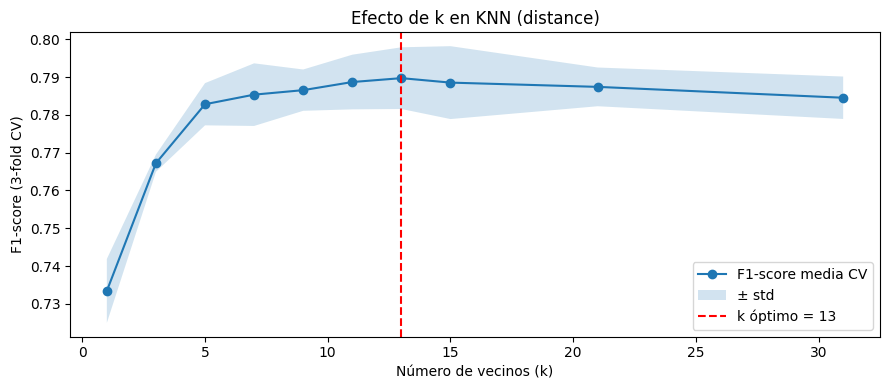

In [156]:
plt.figure(figsize=(9, 4))
# Linea principal
plt.plot(subset_knn["param_knn__n_neighbors"],
         subset_knn["mean_test_score"],
         marker="o", label="F1-score media CV")
# Banda de incertidumbre
plt.fill_between(
    subset_knn["param_knn__n_neighbors"],
    subset_knn["mean_test_score"] - subset_knn["std_test_score"],
    subset_knn["mean_test_score"] + subset_knn["std_test_score"],
    alpha=0.2, label="± std"
)
# k óptimo
plt.axvline(x=grid_knn.best_params_["knn__n_neighbors"],
            color="red", linestyle="--",
            label=f"k óptimo = {grid_knn.best_params_['knn__n_neighbors']}")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("F1-score (3-fold CV)")
plt.title(f"Efecto de k en KNN (distance)")
plt.legend()
plt.tight_layout()
plt.show()

- Con **k=1** el F1 score en CV es ~0.74, notablemente inferior al 
  resto: el modelo memoriza los train (compuestos por 2 folds cada vez) y generaliza mal, aunque la banda de desviación típica es baja (para todas las iteraciones de la validación cruzada tiene un f1 score bajo).
- Entre **k=1 y k=7** el f1 score sube rápidamente (~0.74 → ~0.78): 
  añadir más vecinos reduce el ruido y mejora la generalización de 
  forma muy significativa. Pero la banda de desviación típica se ensancha, indicando mucha diferencia entre los folds.
- Entre **k=7 y k=13**:hay poca diferencia entre diferentes valores de k, no cambiando mucho la media de f1 score, ni la desviación típica.
- El máximo de f1 medio se alcanza en **k=13** (0.7897), aunque la diferencia con valores vecinos no es tanta.
- Para **k>13**, la desviación típica aumenta y los valores medios de f1 score se reducen ligeramente, apuntando a una tendencia de **underfitting** si k aumentase más.

Vemos que hay diferencias entre los diferentes valores de la desviación típica. Para tener esto en cuenta y coger un valor de k más robusto usamos el criterio **mean - std**, penalizando valores de k con alta varianza:

In [157]:
subset_knn["score_estable"] = subset_knn["mean_test_score"] - subset_knn["std_test_score"]

print(subset_knn[["param_knn__n_neighbors", "mean_test_score", "std_test_score", "score_estable"]].to_string(index=False))

 param_knn__n_neighbors  mean_test_score  std_test_score  score_estable
                      1         0.733417        0.008455       0.724962
                      3         0.767210        0.002280       0.764930
                      5         0.782811        0.005584       0.777228
                      7         0.785349        0.008284       0.777065
                      9         0.786538        0.005466       0.781072
                     11         0.788686        0.007228       0.781458
                     13         0.789716        0.008160       0.781555
                     15         0.788533        0.009642       0.778891
                     21         0.787405        0.005122       0.782282
                     31         0.784529        0.005612       0.778917


Aun haciendo esta correción, **k=13** sigue siendo el valor con mejor score_stable (0.7815), haciendolo el mejor valor de k.

## 3.4. Árboles de decisión

### 3.4.1. Preprocesado para árboles

Los árboles, al no utilizar distancias **no es necesario escalado**. 
Hacemos imputación para variables numéricas (aunque no hay nulls, lo incluimos por robustez), el cat_preprocessor para variables categóricas, así como pdays_preprocessor para `pdays`.

Podría debatirse si compensa para las numéricas utilizar `IterativeImputer` o `KNNImputer`, pero para un bajisimo porcentaje de nulos que se espera es añadir complejidad sin motivo aparente.

`month` es más conveniente utilizarla como una variable categórica (como viene originalmente), realizando un OHE normal, ya que no aporta valor a los arboles la encodificación cíclica.

In [158]:
cat_atrib_tree = ["job", "marital", "education", "default", "housing",
                  "loan", "contact", "month", "poutcome"]

preprocessor_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_atrib),
    ("pdays_p", pdays_preprocessor, ["pdays"]),
    ("cat", cat_preprocessor, cat_atrib_tree)
])

### 3.4.2. Árbol poco profundo: interpretación

Antes de optimizar el árbol, entrenamos uno con `max_depth=3`. 

Esto nos ayuda a entender qué variables usa el modelo y con qué umbrales toma 
decisiones. Con solo 3 niveles (máximo 8 hojas) el árbol es 
completamente legible.

Preprocesamos X_train para entrenar el arbol directamente (fuera del pipeline para poder visualizarlo)

In [159]:
X_train_transformed = preprocessor_tree.fit_transform(X_train, y_train)

Obtenemos los nombres de features tras OHE:
- num_atrib (sin transformación de nombres)
- pdays_preprocessor: categorías del OHE de pdaysRange
- cat_preprocessor: OHE de cat_atrib_tree (incluye month)

In [160]:
ohe_pdays = preprocessor_tree.named_transformers_["pdays_p"].named_steps["onehot"]
pdays_feature_names = ohe_pdays.get_feature_names_out(["pdays"]).tolist()

ohe_cat = preprocessor_tree.named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe_cat.get_feature_names_out(cat_atrib_tree).tolist()

feature_names = num_atrib + pdays_feature_names + cat_feature_names


Calculamos el F1 score de manera orientativa:

In [161]:
shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
shallow_tree.fit(X_train_transformed, y_train)

y_pred_shallow = shallow_tree.predict(X_train_transformed)
print(f"F1-score en train (max_depth=3): "
      f"{f1_score(y_train, y_pred_shallow, pos_label='yes'):.4f}")

F1-score en train (max_depth=3): 0.7921


Parece un valor grande pero hay que entender que el F1 del árbol poco profundo sobre train sobreestima, no tiene sentido compararlo directamente con el KNN HPO en CV. La comparación no es válida y puede confundir.

Podemos **visualizar mediante un plot** el árbol, y asi poder interpretarlo:

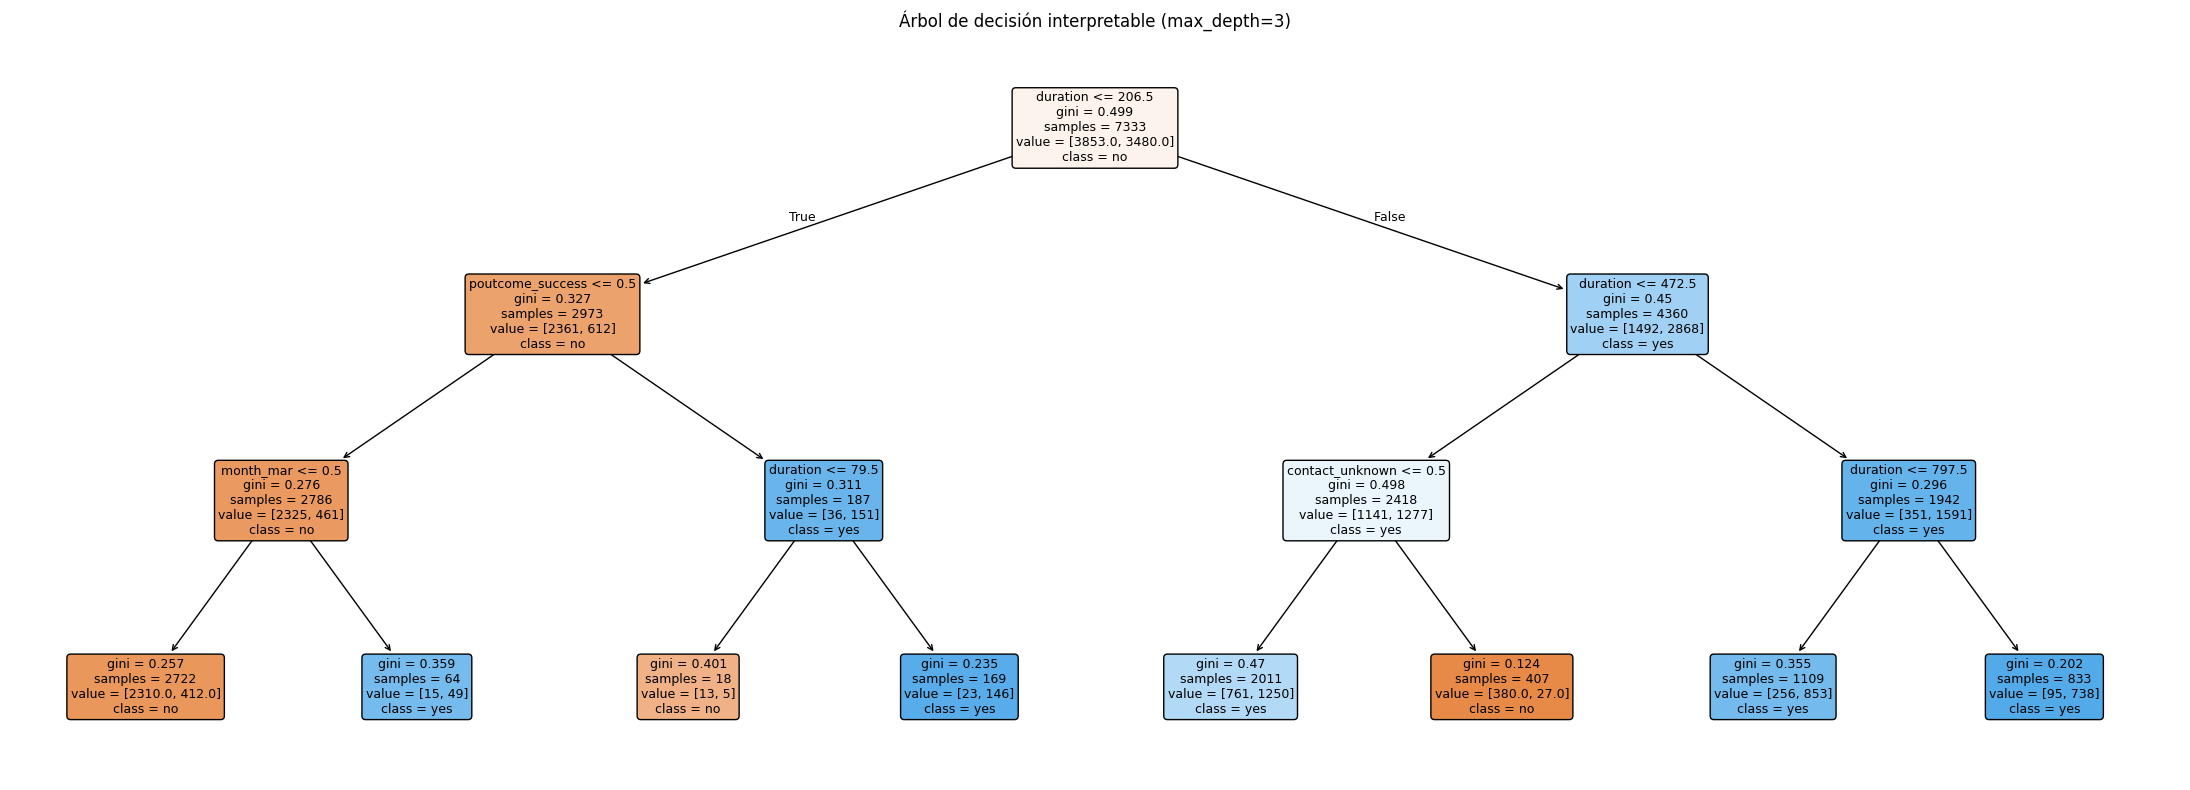

In [162]:
fig, ax = plt.subplots(figsize=(22, 8))
tree.plot_tree(
    shallow_tree,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True, rounded=True, fontsize=9, ax=ax
)
plt.title("Árbol de decisión interpretable (max_depth=3)")
plt.tight_layout()
plt.show()

Podemos también ver cuales son las **variables más importantes**, utilizando la reducción de impureza como métrica:

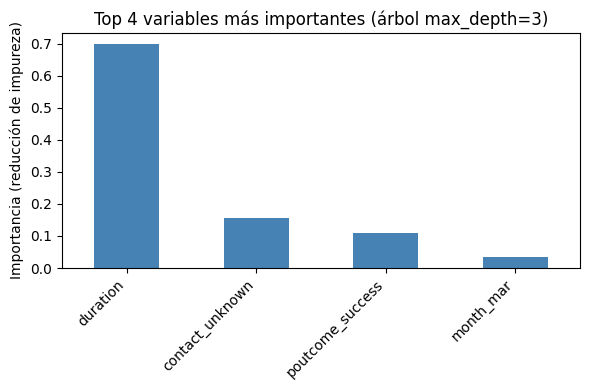

In [163]:
importances = pd.Series(
    shallow_tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(4)

importances.plot.bar(figsize=(6, 4), color="steelblue")
plt.title("Top 4 variables más importantes (árbol max_depth=3)")
plt.ylabel("Importancia (reducción de impureza)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

El árbol con `max_depth=3` revela las reglas de decisión más importantes 
del problema:

- La **primera división** (raíz) usa `duration <= 206.5s`: confirma que 
  es la variable más discriminativa (~0.67 de importancia). Clientes con 
  llamadas cortas (≤206.5s) tienden a no contratar; mientras que, los de llamadas largas 
  tienen alta probabilidad de contratar.

- En la **rama izquierda** (duration ≤ 206.5s, clase mayoritaria *no*): 
  la segunda división usa `poutcome_success`. Los pocos clientes con 
  resultado exitoso en la campaña anterior (solo 187 de 2973) tienen una 
  tasa de conversión muy alta a pesar de haber tenido una llamada corta. 
  Para el resto, el mes de contacto (`month_mar`) marca una diferencia: 
  los contactados en marzo tienen más probabilidad de contratar.

- En la **rama derecha** (duration > 206.5s, clase mayoritaria *yes*): 
  la segunda división añade otro umbral de duración (`duration <= 472.5s`). 
  Para llamadas muy largas (>472.5s) el árbol mira si el contacto fue 
  *unknown* (`contact_unknown`): los clientes contactados por un canal 
  conocido tienen mayor tasa de conversión.

- El gráfico de importancias confirma que **`duration` domina con 
  diferencia** (~ 0.67), seguida de `contact_unknown` (~ 0.17), 
  `poutcome_success` (~ 0.12) y `month_mar` (~ 0.06). El resto de variables 
  tienen importancia prácticamente nula en este árbol poco profundo.

En resumen, el perfil de cliente con más probabilidad de contratar 
el depósito es: **llamada larga + contactado previamente con éxito 
o por canal conocido**. Este árbol, aunque simple, captura la lógica 
principal del problema.

### 3.4.3. Árbol con hiperparámetros por omisión

Evaluamos el árbol sin límite de profundidad como línea base.
Aquí si utilizamos **pipeline**, al no ir a interpretar sus ramas

In [164]:
tree_default = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("tree", DecisionTreeClassifier(random_state=SEED))
])

t0 = time.time()
tree_default_scores = cross_val_score(tree_default, X_train, y_train,
                                      cv=cv, scoring=f1)
t_tree_default = time.time() - t0

print(f"Árbol (default): {tree_default_scores.mean():.4f} ± "
      f"{tree_default_scores.std():.4f} | tiempo: {t_tree_default:.2f}s")

Árbol (default): 0.7570 ± 0.0112 | tiempo: 0.20s


Sorprendentemente, el árbol por omisión (sin límite de profundidad) 
obtiene un F1-score en CV de **0.757**, inferior al árbol interpretable 
de max_depth=3 (**0.792**). Esto es una señal clara de **overfitting**: 
el árbol sin restricciones crece hasta memorizar el train, aprendiendo 
ruido que no generaliza a datos nuevos. 

### 3.4.4. Árbol con HPO

Optimizamos los hiperparámetros más relevantes:
- **`max_depth`**: si es sin limite lleva a overfitting seguro.
- **`min_samples_leaf`**: mínimo de muestras por hoja. Regulariza 
  el árbol evitando divisiones muy específicas del train.
- **`criterion`**: función de impureza (*gini* o *entropy*).

In [165]:
param_grid_tree = {
    "tree__max_depth":        [2, 3, 4, 5, 6, 8, 10, 15, None],
    "tree__min_samples_leaf": [1, 5, 10, 20, 30, 40],
    "tree__criterion":        ["gini", "entropy"]
}

tree_pipeline_hpo = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("tree", DecisionTreeClassifier(random_state=SEED))
])

Usamos GridSearch para probar todas las combinaciones posibles de hiperparametros

In [166]:
t0 = time.time()
grid_tree = GridSearchCV(tree_pipeline_hpo, param_grid_tree,
                         cv=cv, scoring=f1, n_jobs=-1,
                         return_train_score=True, verbose=1)
grid_tree.fit(X_train, y_train)
t_tree_hpo = time.time() - t0

print(f"Mejores hiperparámetros: {grid_tree.best_params_}")
print(f"Mejor F1-score CV:       {grid_tree.best_score_:.4f}")
print(f"Tiempo HPO:              {t_tree_hpo:.2f}s")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores hiperparámetros: {'tree__criterion': 'gini', 'tree__max_depth': 10, 'tree__min_samples_leaf': 30}
Mejor F1-score CV:       0.8133
Tiempo HPO:              8.79s


Dado que el grid inicial usaba saltos grandes, realizamos una **segunda 
búsqueda más fina** alrededor del óptimo encontrado (max_depth=10, 
min_samples_leaf=30, criterion=entropy), fijando ya el criterio y 
explorando valores intermedios para determinar con mayor precisión 
los hiperparámetros óptimos.

In [167]:
param_grid_tree_fine = {
    "tree__max_depth":        [8, 9, 10, 11, 12, 13],
    "tree__min_samples_leaf": [25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35],
    "tree__criterion":        ["entropy"]
}

tree_pipeline_hpo2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("tree", DecisionTreeClassifier(random_state=SEED))
])

t0 = time.time()
grid_tree_fine = GridSearchCV(tree_pipeline_hpo2, param_grid_tree_fine,
                              cv=cv, scoring=f1, n_jobs=-1,
                              return_train_score=True)
grid_tree_fine.fit(X_train, y_train)
t_tree_hpo_fine = time.time() - t0

print(f"Mejores hiperparámetros: {grid_tree_fine.best_params_}")
print(f"Mejor F1-score CV:       {grid_tree_fine.best_score_:.4f}")
print(f"Tiempo HPO fino:         {t_tree_hpo_fine:.2f}s")

Mejores hiperparámetros: {'tree__criterion': 'entropy', 'tree__max_depth': 12, 'tree__min_samples_leaf': 33}
Mejor F1-score CV:       0.8169
Tiempo HPO fino:         5.45s


El óptimo se consolida en max_depth=12 y min_samples_leaf=33. El F1-score en validación alcanza 0.8169 en la búsqueda fina.


### 3.4.5. Efecto del hiperparámetro `max_depth` en el árbol

En primer lugar preparamos los datos para realizar plots que nos permiten explicar visualmente el efecto que tiene `max_depth` en el F1 score. Vamos a ultilizar dos plots diferentes, comparando los valores de la búsqueda amplia y los de la búsqueda fina. 

In [168]:
cv_results_tree      = pd.DataFrame(grid_tree.cv_results_)
cv_results_tree_fine = pd.DataFrame(grid_tree_fine.cv_results_)

best_criterion_wide = grid_tree.best_params_["tree__criterion"]
best_min_leaf_wide  = grid_tree.best_params_["tree__min_samples_leaf"]
best_depth_wide     = grid_tree.best_params_["tree__max_depth"]

best_criterion_fine = grid_tree_fine.best_params_["tree__criterion"]
best_min_leaf_fine  = grid_tree_fine.best_params_["tree__min_samples_leaf"]
best_depth_fine     = grid_tree_fine.best_params_["tree__max_depth"]


Filtramos y ordenamos para la busqueda amplia (se usa fillna para poner 50 a valores None, porque si no no podemos representarlo en un plot):

In [169]:
mask_wide = (
    (cv_results_tree["param_tree__criterion"]        == best_criterion_wide) &
    (cv_results_tree["param_tree__min_samples_leaf"] == best_min_leaf_wide)
)
subset_tree_wide = cv_results_tree[mask_wide].copy()
subset_tree_wide["param_tree__max_depth"] = (
    subset_tree_wide["param_tree__max_depth"].fillna(50)
)
subset_tree_wide = subset_tree_wide.sort_values("param_tree__max_depth")
x_wide = subset_tree_wide["param_tree__max_depth"].astype(float).values

/tmp/ipykernel_853/1502749467.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  subset_tree_wide["param_tree__max_depth"].fillna(50)


Filtramos y ordenamos para la búsqueda fina:

In [170]:
mask_fine = (
    (cv_results_tree_fine["param_tree__criterion"]        == best_criterion_fine) &
    (cv_results_tree_fine["param_tree__min_samples_leaf"] == best_min_leaf_fine)
)
subset_tree_fine = cv_results_tree_fine[mask_fine].copy()
subset_tree_fine = subset_tree_fine.sort_values("param_tree__max_depth")
x_fine = subset_tree_fine["param_tree__max_depth"].astype(float).values

Creamos un plot pareado viendo el efecto de max_depth en F1-score para la busqueda amplia (izquieda) y la fina (derecha). Visualizaremos tanto el F1 del **cross validation** (azul) como el F1 de **train** (rojo), que esta sobrestimado.

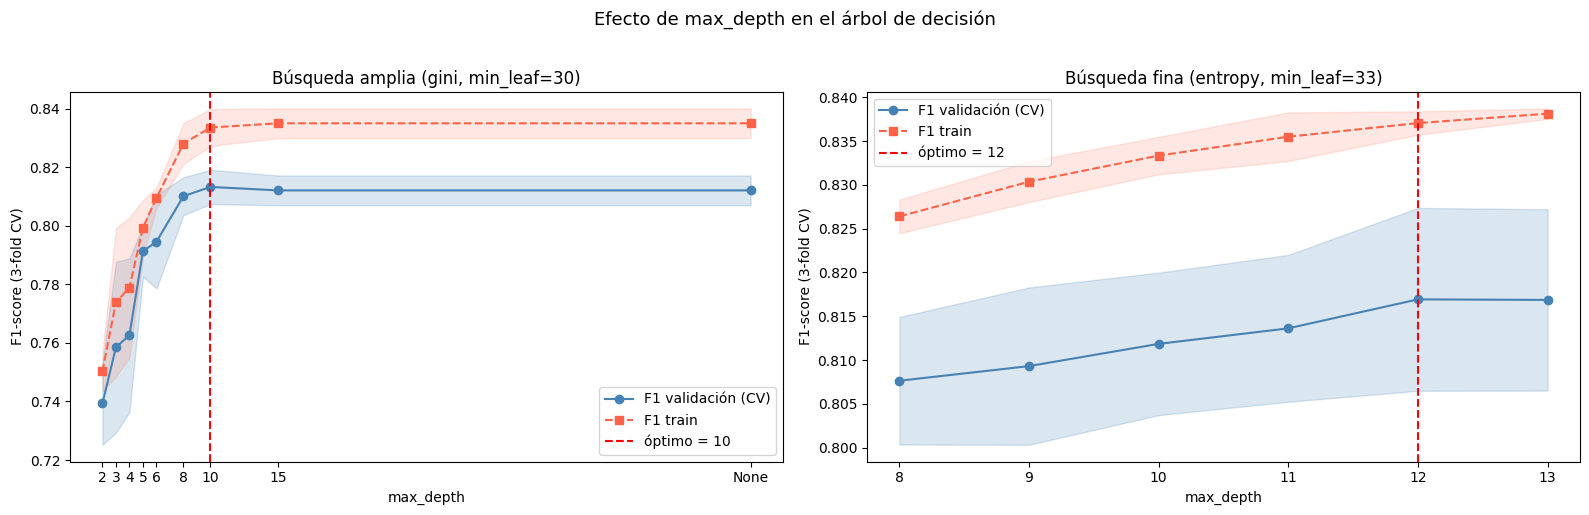

In [171]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Izquierdo: búsqueda amplia
ax = axes[0]
ax.plot(x_wide, subset_tree_wide["mean_test_score"],
        marker="o", color="steelblue", label="F1 validación (CV)")
ax.fill_between(
    x_wide,
    subset_tree_wide["mean_test_score"] - subset_tree_wide["std_test_score"],
    subset_tree_wide["mean_test_score"] + subset_tree_wide["std_test_score"],
    alpha=0.2, color="steelblue"
)
ax.plot(x_wide, subset_tree_wide["mean_train_score"],
        marker="s", color="tomato", linestyle="--", label="F1 train")
ax.fill_between(
    x_wide,
    subset_tree_wide["mean_train_score"] - subset_tree_wide["std_train_score"],
    subset_tree_wide["mean_train_score"] + subset_tree_wide["std_train_score"],
    alpha=0.15, color="tomato"
)
ax.axvline(x=best_depth_wide if best_depth_wide is not None else 50,
           color="red", linestyle="--",
           label=f"óptimo = {best_depth_wide}")
labels_wide = [str(int(t)) if t != 50 else "None" for t in x_wide]
ax.set_xticks(x_wide)
ax.set_xticklabels(labels_wide)
ax.set_xlabel("max_depth")
ax.set_ylabel("F1-score (3-fold CV)")
ax.set_title(f"Búsqueda amplia ({best_criterion_wide}, "
             f"min_leaf={best_min_leaf_wide})")
ax.legend()

# Derecho: búsqueda fina
ax = axes[1]
ax.plot(x_fine, subset_tree_fine["mean_test_score"],
        marker="o", color="steelblue", label="F1 validación (CV)")
ax.fill_between(
    x_fine,
    subset_tree_fine["mean_test_score"] - subset_tree_fine["std_test_score"],
    subset_tree_fine["mean_test_score"] + subset_tree_fine["std_test_score"],
    alpha=0.2, color="steelblue"
)
ax.plot(x_fine, subset_tree_fine["mean_train_score"],
        marker="s", color="tomato", linestyle="--", label="F1 train")
ax.fill_between(
    x_fine,
    subset_tree_fine["mean_train_score"] - subset_tree_fine["std_train_score"],
    subset_tree_fine["mean_train_score"] + subset_tree_fine["std_train_score"],
    alpha=0.15, color="tomato"
)
ax.axvline(x=float(best_depth_fine),
           color="red", linestyle="--",
           label=f"óptimo = {best_depth_fine}")
ax.set_xticks(x_fine)
ax.set_xticklabels([str(int(t)) for t in x_fine])
ax.set_xlabel("max_depth")
ax.set_ylabel("F1-score (3-fold CV)")
ax.set_title(f"Búsqueda fina ({best_criterion_fine}, "
             f"min_leaf={best_min_leaf_fine})")
ax.legend()

plt.suptitle("Efecto de max_depth en el árbol de decisión",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Búsqueda amplia:**

- Con **max_depth=2** hay underfitting claro: tanto F1 train como 
  validación son bajos (~ 0.74), con una brecha pequeña entre ambos. 
  El árbol es demasiado simple para capturar la complejidad del problema.
- Entre **max_depth=2 y max_depth=10** la validación crece rápidamente, 
  siendo la zona donde más se beneficia de aumentar la profundidad. 
  El F1 train también sube pero más rápido, y la brecha entre train 
  y validación empieza a abrirse.
- A partir de **max_depth=10** la validación se estabiliza (~0.82) 
  mientras el F1 train sigue subiendo (~ 0.837), lo que indica que 
  el árbol empieza a memorizar ruido del train sin mejorar la 
  generalización. La brecha train-validación se consolida.
- Con **max_depth=None** la validación no mejora respecto a max_depth=10 
  pero el F1 train se mantiene alto, confirmando overfitting. El árbol 
  sin límite no generaliza mejor que con max_depth=10.

**Búsqueda fina:**

- Confirma que **max_depth=12** es el óptimo: es el punto donde la 
  validación alcanza su máximo (~ 0.8169) y la brecha train-validación 
  es razonable.
- Para max_depth > 12 la validación decrece ligeramente (~0.815) 
  mientras el F1 train sigue creciendo, confirmando que más profundidad 
  solo añade overfitting sin mejorar la generalización.
- La banda de desviación típica en validación es amplia, lo que indica 
  cierta variabilidad entre folds. Esto es esperable con solo 3 folds.

Este problema requiere una profundidad moderada (**max_depth=12**). Valores muy bajos producen underfitting y valores muy altos o sin límite producen overfitting. 

El árbol interpretable de max_depth=3 que usamos para entender el problema era demasiado simple para maximizar el rendimiento, aunque servía perfectamente para la interpretación.

### 3.4.6. Interacción de `max_depth` y `min_samples_leaf` en el árbol

Filtramos para el mejor criterion y creamos dos tablas pivote (para búsqueda fina y amplia):
- **filas** = valores de min_samples_leaf
- **columnas** = valores de max_depth
- **valores** = F1-score medio en CV

Esto nos permite ver la interacción entre ambos hiperparámetros: cómo cambia la accuracy según la combinación de los dos

In [172]:
pivot_wide = cv_results_tree[
    cv_results_tree["param_tree__criterion"] == best_criterion_wide
].pivot_table(
    index="param_tree__min_samples_leaf",
    columns="param_tree__max_depth",
    values="mean_test_score"
)

pivot_fine = cv_results_tree_fine[
    cv_results_tree_fine["param_tree__criterion"] == best_criterion_fine
].pivot_table(
    index="param_tree__min_samples_leaf",
    columns="param_tree__max_depth",
    values="mean_test_score"
)

Creamos dos heatmaps que nos permiten ver la interacción entre los dos hiperparámetros 

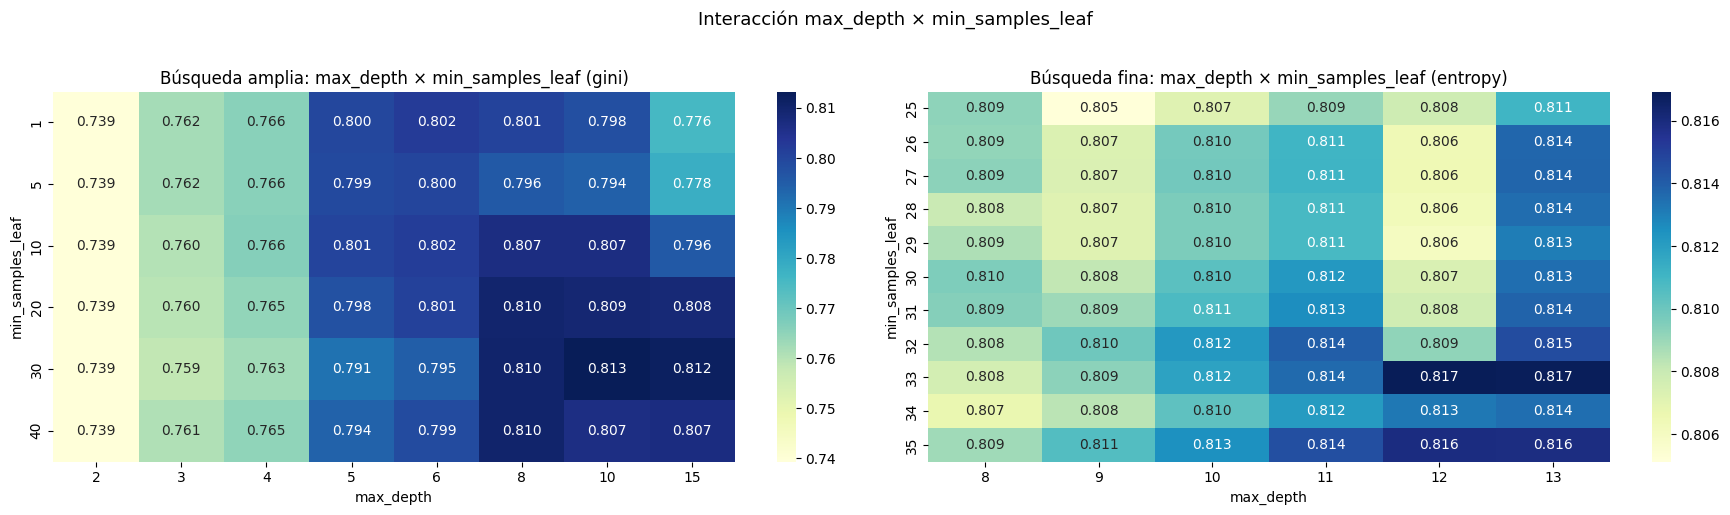

In [173]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# --- Izquierdo: búsqueda amplia ---
sns.heatmap(pivot_wide, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title(f"Búsqueda amplia: max_depth × min_samples_leaf "
                  f"({best_criterion_wide})")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("min_samples_leaf")

# --- Derecho: búsqueda fina ---
sns.heatmap(pivot_fine, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title(f"Búsqueda fina: max_depth × min_samples_leaf "
                  f"({best_criterion_fine})")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("min_samples_leaf")

plt.suptitle("Interacción max_depth × min_samples_leaf",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Búsqueda amplia:**

- **`max_depth` es el hiperparámetro dominante**: el color cambia 
  drásticamente en el eje horizontal (de ~0.74 con max_depth=2 a 
  ~0.812 con max_depth=15), mientras que las diferencias verticales 
  entre valores de `min_samples_leaf` son mínimas para un mismo 
  max_depth.
- Con **max_depth ≤ 4** todos los valores de `min_samples_leaf` dan 
  resultados casi idénticos (~0.739-0.766): el árbol es tan simple 
  que la regularización adicional de `min_samples_leaf` no tiene 
  efecto.
- Con **max_depth=10** se alcanza el máximo (~0.813 con 
  min_samples_leaf=30).
- **min_samples_leaf=40** penaliza ligeramente en profundidades altas: 
  restringir demasiado el tamaño de las hojas impide que el árbol 
  aproveche su profundidad.

**Búsqueda fina:**

- Las diferencias entre celdas son muy pequeñas (rango 0.806-0.817), 
  confirmando que estamos en la zona de máximo rendimiento y que 
  pequeñas variaciones de ambos hiperparámetros tienen impacto mínimo.
- El óptimo **max_depth=12, min_samples_leaf=33** (0.8169) destaca 
  ligeramente.
- La zona más oscura se concentra en torno a **max_depth=12-13 y min_samples_leaf=33**, lo que da robustez a la elección: 
  no dependemos de un único punto óptimo sino de una región estable.
- Cabe destacar que con **min_samples_leaf=33 y max_depth=13** se obtiene un valor muy próximo de
F1-score (0.817) que con **max_depth=12**. Sin embargo, preferimos con 12 de profundidad al ser menos complejidad.

## 3.5. Conclusiones de los métodos básicos

**Tabla resumen final**: comparamos todos los modelos de la sección en una sola tabla: dummy (baseline), defaults y HPO de KNN y árbol

In [174]:
print(f"\n{'Modelo':<35} {'F1 CV':>10} {'Tiempo':>12}")
print("-" * 60)
print(f"{'Dummy (stratified)':<35} {dummy_scores.mean():>10.4f} {'N/A':>12}")
print(f"{'KNN (default, k=5)':<35} {knn_default_scores.mean():>10.4f} {t_knn_default:>11.2f}s")
print(f"{'KNN (HPO, k=13)':<35} {grid_knn.best_score_:>10.4f} {t_knn_hpo:>11.2f}s")
print(f"{'Árbol (default)':<35} {tree_default_scores.mean():>10.4f} {t_tree_default:>11.2f}s")
print(f"{'Árbol (HPO amplio)':<35} {grid_tree.best_score_:>10.4f} {t_tree_hpo:>11.2f}s")
print(f"{'Árbol (HPO fino)':<35} {grid_tree_fine.best_score_:>10.4f} {t_tree_hpo_fine:>11.2f}s")


Modelo                                   F1 CV       Tiempo
------------------------------------------------------------
Dummy (stratified)                      0.4836          N/A
KNN (default, k=5)                      0.7815        0.20s
KNN (HPO, k=13)                         0.7897        4.11s
Árbol (default)                         0.7570        0.20s
Árbol (HPO amplio)                      0.8133        8.79s
Árbol (HPO fino)                        0.8169        5.45s


**¿Superan al modelo trivial?**

Sí. Tanto KNN como el árbol superan claramente al dummy (F1=0.48), 
confirmando que ambos capturan información real del problema. El dummy 
con `strategy="stratified"` ya refleja que predecir aleatoriamente 
respetando la distribución de clases da un F1 muy bajo, y cualquier 
modelo que aprenda algo real debe superarlo con claridad.

**¿El HPO mejora respecto a los valores por omisión?**

- En **KNN**: la mejora es moderada (0.7815 → 0.7897). 
  El k=5 por omisión ya era razonable, pero el HPO encuentra k=13 
  con mejor equilibrio entre rendimiento y estabilidad (criterio 
  mean-std).
- En **árboles**: la mejora es muy notable (0.7570 → 0.8169). 
  El árbol por omisión hacía overfitting claro al crecer sin límite; 
  limitar max_depth=12 y min_samples_leaf=33 es la decisión clave. 
  El HPO fino además mejora ligeramente al amplio (0.8133 → 0.8169).

**¿El coste computacional del HPO está justificado?**

Sí en ambos casos. KNN tarda ~5s y el árbol ~15s en total 
(amplio + fino), tiempos muy razonables teniendo en cuenta que esto solo se realiza una vez para decidir los hiperparametros mejores. Al entrenar al modelo real no se vuelve a hacer tantas iteraciones.

**¿Los árboles necesitan profundidades altas o bajas?**

Moderadas. El óptimo es max_depth=12: valores bajos producen 
underfitting y sin límite produce overfitting claro, con una brecha 
train-validación notable. A partir de max_depth=12 la validación 
se estabiliza mientras train sigue subiendo.

**¿Cuántos vecinos necesita KNN?**

Un valor moderado: k=13. Con k=1 hay overfitting claro y con valores 
muy altos se pierden patrones locales. Aplicando el criterio mean-std, 
k=13 ofrece mejor equilibrio entre rendimiento y estabilidad que el 
k óptimo de GridSearchCV.

**¿Cuál es el mejor método?**

El **árbol con HPO fino** (F1=0.8169) supera claramente al KNN con 
HPO (F1=0.7897), siendo además más rápido de entrenar. Adicionalmente, 
el árbol ofrece **interpretabilidad**: como vimos con el árbol de 
max_depth=3, es posible entender las reglas de decisión del modelo, 
algo imposible con KNN.

# 4. Métodos avanzados: modelos lineales y SVMs

En esta sección exploramos modelos que asumen fronteras de decisión paramétricas (lineales) y modelos de margen máximo (SVM). A diferencia de los árboles, estos modelos son altamente dependientes del escalado de variables, por lo que utilizaremos el `preprocessor_final` basado en `StandardScaler`.

## 4.1. Modelos Lineales

En esta sección evaluamos la **Regresión Logística**, un modelo que asume una relación lineal entre las variables y el logaritmo de las probabilidades de la clase. Compararemos:
- **Sin regularización**: El modelo intenta ajustarse lo máximo posible a los datos de entrenamiento.
- **Con regularización L1 (Lasso)**: Útil para la selección de atributos, ya que puede reducir a cero los coeficientes de las variables menos importantes.

### 4.1.1. Modelo lineal sin regularización

Entrenamos el modelo sin penalización (`penalty=None`). Esto permite que los coeficientes crezcan libremente para ajustarse a los datos, lo cual es útil como baseline pero propenso a varianza si hay ruido.

In [175]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

lr_none = Pipeline([
    ('preprocessor', preprocessor_final),
    ('lr', LogisticRegression(C=np.inf, max_iter=1000, random_state=SEED))
])

t0 = time.time()
scores_lr_none = cross_val_score(lr_none, X_train, y_train, cv=cv, scoring=f1)
t_lr_none = time.time() - t0

print(f'LR (Sin reg) F1: {scores_lr_none.mean():.4f} ± {scores_lr_none.std():.4f}')
print(f'Tiempo: {t_lr_none:.2f}s')

/home/iav/universidad/aprendizaje automatico/UC3M-ML-P1-03/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/iav/universidad/aprendizaje automatico/UC3M-ML-P1-03/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/iav/universidad/aprendizaje automatico/UC3M-ML-P1-03/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


LR (Sin reg) F1: 0.7903 ± 0.0077
Tiempo: 0.30s


> No nos deben preocupar los warnings, puesto que no son relevantes.

El modelo base de regresión logística obtiene un **F1-score de 0.7903**. Este valor es competitivo, superando ligeramente al KNN optimizado, lo que sugiere que las fronteras de decisión lineales se adaptan bien a la distribución de este dataset. 

Al no tener penalización, el tiempo de entrenamiento es mínimo (~0.5s), estableciendo un punto de referencia sólido para observar si la regularización L1 aporta mejoras significativas en la generalización o en la selección de atributos.

### 4.1.2. Modelo lineal con regularización L1

Evaluamos ahora el modelo con regularización **L1 (Lasso)** por defecto ($C=1.0$). La regularización L1 tiene la propiedad de realizar selección de variables al forzar algunos coeficientes a cero.

In [176]:
lr_l1_def = Pipeline([
    ('preprocessor', preprocessor_final),
    ('lr', LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, random_state=SEED))
])

t0 = time.time()
scores_lr_l1_def = cross_val_score(lr_l1_def, X_train, y_train, cv=cv, scoring=f1)
t_lr_l1_def = time.time() - t0

print(f'LR (L1 Default) F1: {scores_lr_l1_def.mean():.4f} | Tiempo: {t_lr_l1_def:.2f}s')

LR (L1 Default) F1: 0.7908 | Tiempo: 0.30s


Al aplicar la regularización L1 con el parámetro por defecto ($C=1.0$), el rendimiento mejora ligeramente hasta un **F1-score de 0.7908**. Aunque el incremento respecto al modelo sin regularización es pequeño (~ 0.0005), esta mejora sugiere que la penalización de coeficientes ayuda a reducir la varianza y mejora la capacidad de generalización del modelo, manteniendo un coste computacional similar (~ 0.4s).

### 4.1.3. Ajuste de hiperparametros de modelo lineal L1

#### 4.1.3.1. Búsqueda amplia de *C*

Vamos a ralizar un ajuste del hiperparámetro $C$ (inverso de la fuerza de regularización). Valores pequeños de $C$ implican una regularización fuerte. Por supuesto, esto solo lo realizamos sobre el modelo con regularización.

In [177]:
param_grid_l1 = {'lr__C': [0.001, 0.01, 0.1, 1, 10, 100]}
lr_l1_pipe = Pipeline([
    ('preprocessor', preprocessor_final),
    ('lr', LogisticRegression(l1_ratio=1, solver='liblinear', max_iter=1000, random_state=SEED))
])

grid_l1 = GridSearchCV(lr_l1_pipe, param_grid_l1, cv=cv, scoring=f1, return_train_score=True, n_jobs=-1)
grid_l1.fit(X_train, y_train)

print(f'Mejor C para L1: {grid_l1.best_params_["lr__C"]}')
print(f'Mejor F1 CV: {grid_l1.best_score_:.4f}')

Mejor C para L1: 0.1
Mejor F1 CV: 0.7930


### 4.1.3.2. Búsqueda fina de *C*

Dado que el óptimo inicial se situó en un rango cercano 0.1, realizamos una búsqueda más exhaustiva en el intervalo [0.05, 0.5] para refinar el parámetro $C$. Probando 20 valores entre estos dos valores:

In [178]:
param_grid_l1_fine = {'lr__C': np.linspace(0.01, 0.5, 20)}

t0 = time.time()
grid_l1_fine = GridSearchCV(lr_l1_pipe, param_grid_l1_fine, cv=cv, scoring=f1, n_jobs=-1, return_train_score=True)
grid_l1_fine.fit(X_train, y_train)
t_l1_fine = time.time() - t0

print(f'Mejor C refinado: {grid_l1_fine.best_params_["lr__C"]:.4f}')
print(f'Mejor F1 CV (fino): {grid_l1_fine.best_score_:.4f}')
print(f'Tiempo HPO fino: {t_l1_fine:.2f}s')

Mejor C refinado: 0.1389
Mejor F1 CV (fino): 0.7940
Tiempo HPO fino: 2.37s


Tras realizar la búsqueda fina para Regresión Logística, el valor óptimo de **C se sitúa en 0.1389**, logrando un **F1-score de 0.7940**.

### 4.1.4. Como afectan hiperparámetros (L1)

Analizamos la curva de aprendizaje variando $C$. Observamos cómo evoluciona el F1 tanto en entrenamiento como en validación.

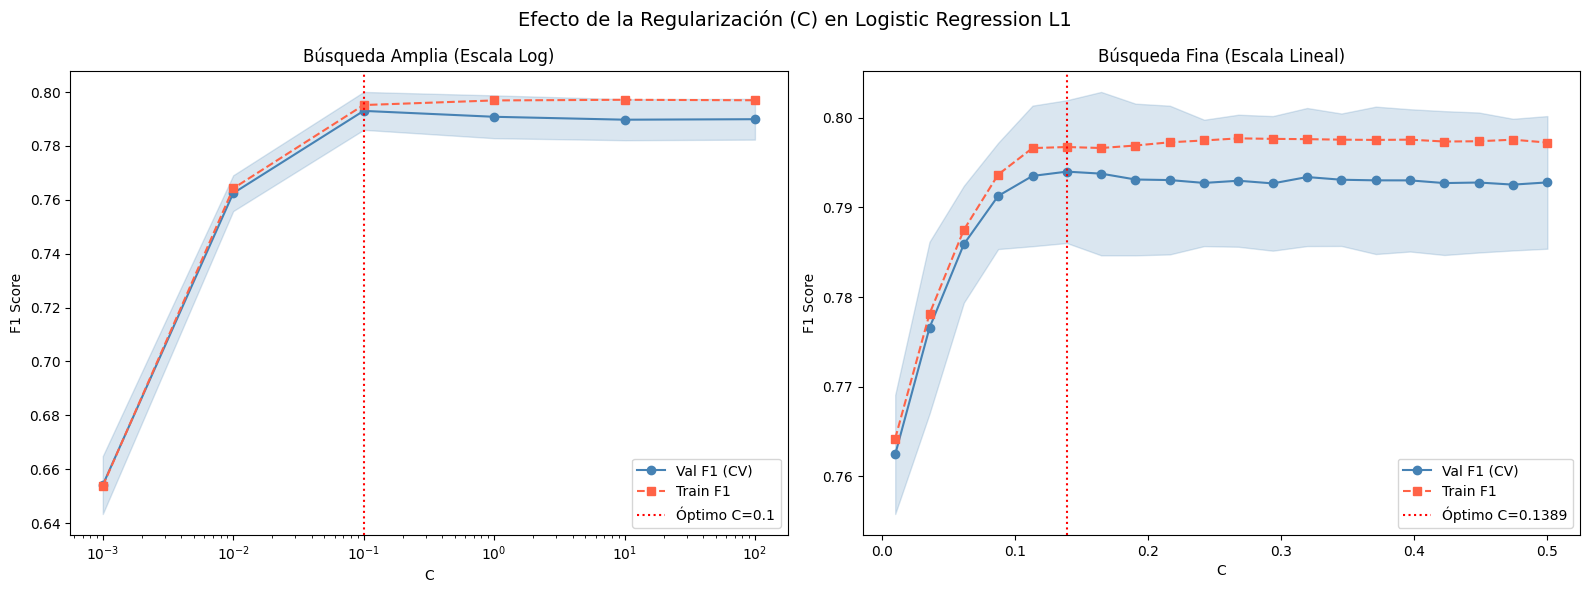

In [179]:
res_l1_wide = pd.DataFrame(grid_l1.cv_results_)
res_l1_fine = pd.DataFrame(grid_l1_fine.cv_results_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Búsqueda Amplia ---
ax1.semilogx(res_l1_wide['param_lr__C'], res_l1_wide['mean_test_score'], label='Val F1 (CV)', marker='o', color='steelblue')
ax1.fill_between(res_l1_wide['param_lr__C'].astype(float),
                 res_l1_wide['mean_test_score'] - res_l1_wide['std_test_score'],
                 res_l1_wide['mean_test_score'] + res_l1_wide['std_test_score'], alpha=0.2, color='steelblue')
ax1.semilogx(res_l1_wide['param_lr__C'], res_l1_wide['mean_train_score'], label='Train F1', marker='s', linestyle='--', color='tomato')
ax1.axvline(grid_l1.best_params_['lr__C'], color='red', linestyle=':', label=f'Óptimo C={grid_l1.best_params_["lr__C"]}')
ax1.set_title('Búsqueda Amplia (Escala Log)')
ax1.set_xlabel('C')
ax1.set_ylabel('F1 Score')
ax1.grid(False)
ax1.legend(loc='lower right')

# --- Plot 2: Búsqueda Fina ---
ax2.plot(res_l1_fine['param_lr__C'], res_l1_fine['mean_test_score'], label='Val F1 (CV)', marker='o', color='steelblue')
ax2.fill_between(res_l1_fine['param_lr__C'].astype(float),
                 res_l1_fine['mean_test_score'] - res_l1_fine['std_test_score'],
                 res_l1_fine['mean_test_score'] + res_l1_fine['std_test_score'], alpha=0.2, color='steelblue')
ax2.plot(res_l1_fine['param_lr__C'], res_l1_fine['mean_train_score'], label='Train F1', marker='s', linestyle='--', color='tomato')
ax2.axvline(grid_l1_fine.best_params_['lr__C'], color='red', linestyle=':', label=f'Óptimo C={grid_l1_fine.best_params_["lr__C"]:.4f}')
ax2.set_title('Búsqueda Fina (Escala Lineal)')
ax2.set_xlabel('C')
ax2.set_ylabel('F1 Score')
ax2.grid(False)
ax2.legend(loc='lower right')

plt.suptitle('Efecto de la Regularización (C) en Logistic Regression L1', fontsize=14)
plt.tight_layout()
plt.show()

El análisis visual mediante los dos gráficos comparativos permite extraer conclusiones clave sobre el comportamiento del modelo lineal:

-  **Búsqueda Amplia (Escala Logarítmica):**
    *   **Identificación del rango:** La escala logarítmica es fundamental aquí para observar cómo el modelo reacciona ante cambios drásticos en la fuerza de regularización.
    *   **Estabilidad:** Se observa que para valores de $C$ muy pequeños ($< 0.01$), el modelo sufre de *underfitting* extremo (fuerte regularización), con F1-scores bajos. A partir de $C=0.1$, el rendimiento se estabiliza en una meseta, lo que indica que el modelo no es excesivamente sensible a variaciones de magnitud una vez superado el umbral crítico.

- **Búsqueda Fina (Escala Lineal):**
    *   **Localización del óptimo:** Al hacer 'zoom' en el rango [0.01, 0.5] con una escala lineal, podemos apreciar la curvatura real del rendimiento. El pico de la validación se localiza de forma precisa en **$C = 0.1389$** logrando un **F1-score de 0.794**.
    *   **Diagnóstico de Overfitting:** La brecha entre la curva de *Train* (roja) y *Validación* (azul) es pequeña y constante. Esto sugiere que el modelo generaliza correctamente y que la regularización L1 está cumpliendo su función de mantener los pesos bajo control sin 'memorizar' el ruido del conjunto de entrenamiento.

 Las **bandas de desviación típica** (sombreados) son relativamente estrechas en ambas gráficas. Esto indica que el rendimiento del modelo es consistente a través de los diferentes *folds* de la validación cruzada.

### 4.1.5. Analisis de Relevancia de Atributos

Hacemos una reconstrucción manual de nombres de atributos y hacemos un análisis de los coeficientes para saber en primer lugar cuales son los atributos **con coeficiente 0 (no relevantes)** y los que tienen **coeficiente diferente de 0 (relevantes)**.

In [180]:
best_estimator = grid_l1.best_estimator_
best_lr = best_estimator.named_steps['lr']
fitted_preprocessor = best_estimator.named_steps['preprocessor']

# 1. Reconstrucción manual de nombres de atributos
feat_names = num_atrib.copy()
feat_names += ['month_sin', 'month_cos']
ohe_pdays = fitted_preprocessor.named_transformers_['pdays_p'].named_steps['onehot']
feat_names += ohe_pdays.get_feature_names_out(['pdays']).tolist()
ohe_cat = fitted_preprocessor.named_transformers_['cat'].named_steps['onehot']
feat_names += ohe_cat.get_feature_names_out(cat_atrib).tolist()

# 2. Análisis de coeficientes
coefs_all = pd.DataFrame({'feature': feat_names, 'coef': best_lr.coef_[0]})
n_nonzero = np.count_nonzero(coefs_all['coef'])
zero_feats = coefs_all[coefs_all['coef'] == 0]['feature'].tolist()

print(f"Atributos con coeficiente diferente de 0: {n_nonzero}")
print(f"Atributos con coeficiente igual a 0: {len(zero_feats)}")

# Imprime cada atributo en una nueva línea con un guion
print("\nNombres de los atributos eliminados (coef=0):")
for feat in zero_feats:
    print(f"  - {feat}")

Atributos con coeficiente diferente de 0: 28
Atributos con coeficiente igual a 0: 20

Nombres de los atributos eliminados (coef=0):
  - pdays_1_trimestre
  - pdays_2_trimestre
  - pdays_3_trimestre
  - job_entrepreneur
  - job_housemaid
  - job_management
  - job_services
  - job_technician
  - job_unemployed
  - job_unknown
  - marital_divorced
  - education_secondary
  - education_unknown
  - default_no
  - default_yes
  - contact_cellular
  - contact_telephone
  - poutcome_failure
  - poutcome_other
  - poutcome_unknown


Hacemos una gráfica para visualizar los **28 atributos relevantes** de manera gráfica, ordenándolos por coeficiente positivo y negativo y la magnitud de su coeficiente:

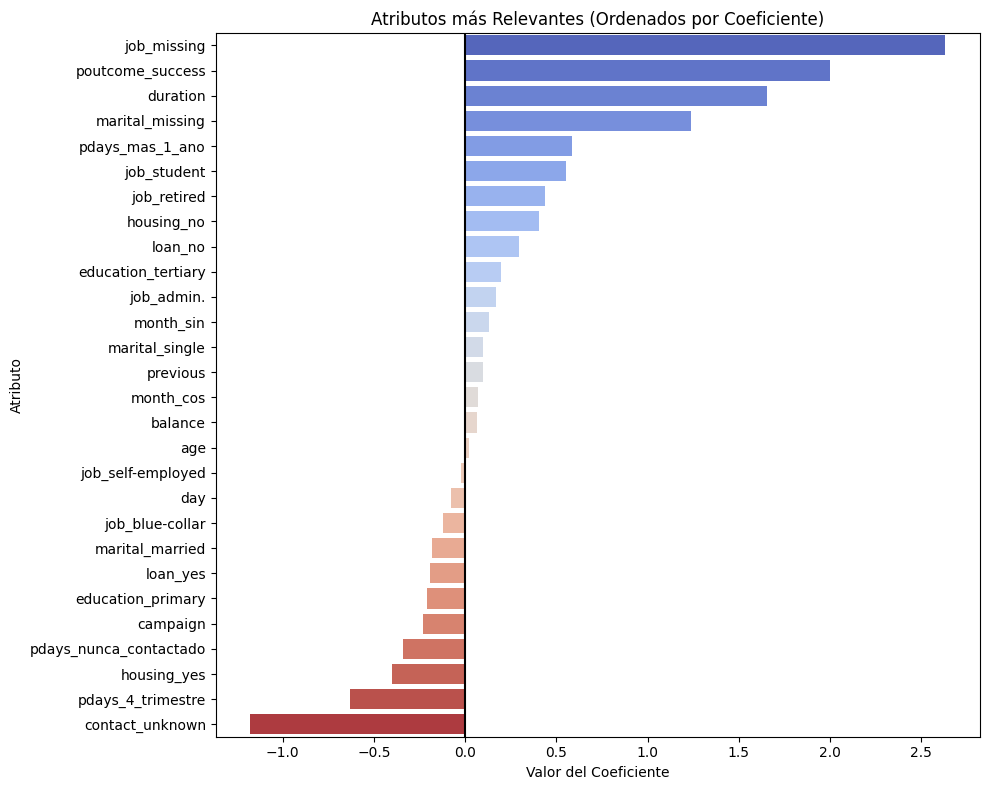

In [181]:
coefs_all['abs_coef'] = coefs_all['coef'].abs()
relevant_atrib = coefs_all.sort_values('abs_coef', ascending=False).head(28)

relevant_atrib = relevant_atrib.sort_values('coef', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=relevant_atrib, x='coef', y='feature', palette='coolwarm', hue='feature', legend=False)
plt.title('Atributos más Relevantes (Ordenados por Coeficiente)')
plt.axvline(0, color='black', lw=1.5)
plt.xlabel('Valor del Coeficiente')
plt.ylabel('Atributo')
plt.tight_layout()
plt.show()

Los coeficientes **positivos** (azul) favorecen *yes* y los 
**negativos** (rojo) favorecen *no*.

**Atributos más relevantes para contratar (*yes*):**
- **`job_missing`** (~2.6): el coeficiente más alto. Valida la 
  decisión de imputar con "missing": los clientes con trabajo 
  desconocido tienen mayor tasa de conversión.
- **`poutcome_success`** (~2.0): resultado exitoso en campaña 
  anterior → alta probabilidad de contratar. Consistente con el EDA.
- **`duration`** (~1.75): variable numérica más importante, 
  consistente con todos los modelos anteriores.
- **`marital_missing`** (~1.25): igual que `job_missing`, los 
  clientes con estado civil desconocido tienden más a contratar. 
- **`pdays_mas_1_ano`** (~0.6),**`job_student`**(~0.55), **`job_retired`**
  y **`housing_no`** (~0.5): consistentes con el EDA.

**Atributos que desfavorecen la contratación (*no*):**
- **`contact_unknown`** (~-1.2): mayor coeficiente negativo. 
  Canal desconocido → muy baja probabilidad de contratar.
- **`pdays_4_trimestre`** (~-0.6): contactados hace 9-12 meses 
  tienen menor probabilidad. Contrasta con `pdays_mas_1_ano` 
  positivo, sugiriendo un efecto no lineal del tiempo.
- **`housing_yes`**, **`loan_yes`**, **`marital_married`**, 
  **`campaign`**: todos negativos y consistentes con el EDA.

**Conclusión**: L1 realiza una selección coherente con el EDA. 
Destaca especialmente que `job_missing` y `marital_missing` sean de
los coeficientes más altos, validando que tratar los missings como 
categoría propia captura un patrón real que la imputación por moda 
habría eliminado. Vemos que para `job` hay mucha diferencia de relevancia
entre `missing` y `unknown`,**que es eliminado por el algoritmo L1**.

## 4.2. SVMs

Las Máquinas de Vector de Soporte buscan un hiperplano que maximice la separación entre clases, utilizando opcionalmente kernels para manejar no linealidades.

### 4.2.1. SVM con kernel lineal e hiperparámetros por omisión

Evaluamos el rendimiento del clasificador SVM utilizando un kernel lineal y el parámetro de penalización por defecto ($C=1$). Al igual que con los modelos anteriores, utilizamos el preprocesador basado en `StandardScaler`.

In [182]:
svm_linear_def = Pipeline([
    ('preprocessor', preprocessor_final),
    ('svc', SVC(kernel='linear', C=1.0, random_state=SEED))
])

t0 = time.time()
scores_svm_linear_def = cross_val_score(svm_linear_def, X_train, y_train, cv=cv, scoring=f1)
t_svm_linear_def = time.time() - t0

print(f'SVM Linear (Default C=1) F1: {scores_svm_linear_def.mean():.4f} \u00b1 {scores_svm_linear_def.std():.4f}')
print(f'Tiempo: {t_svm_linear_def:.2f}s')

SVM Linear (Default C=1) F1: 0.7969 ± 0.0118
Tiempo: 1.92s


### 4.2.2. HPO de SVM lineal

Realizamos un ajuste de HPO del hiperparámetro $C$, siendo la penalización del error u holguras.

In [183]:
param_grid_svm_linear = {'svc__C': [0.01, 0.1, 1, 10, 100]}

svm_linear_pipe = Pipeline([
    ('preprocessor', preprocessor_final),
    ('svc', SVC(kernel='linear', random_state=SEED))
])

grid_svm_linear = GridSearchCV(svm_linear_pipe, param_grid_svm_linear, cv=cv, scoring=f1, n_jobs=-1)
t0 = time.time()
grid_svm_linear.fit(X_train, y_train)
t_svm_linear = time.time() - t0

print(f'Mejor C (Kernel Lineal): {grid_svm_linear.best_params_["svc__C"]}')
print(f'Mejor F1 CV (Lineal): {grid_svm_linear.best_score_:.4f}')
print(f'Tiempo: {t_svm_linear:.2f}s')

Mejor C (Kernel Lineal): 0.1
Mejor F1 CV (Lineal): 0.7970
Tiempo: 20.71s


Realizando un ajuste de hiperparámetros sobre el SVM lineal, obtenemos un **F1 score = 0.7970**, lo cual sigue siendo peor que los árboles de decisión con HPO (0.8169).

### 4.2.3. Con kernel RBF e hiperparametros por omisión

Evaluamos el SVC con kernel RBF y valores por defecto ($C=1$, $\gamma=scale$). Este permite calcular la similitud en un espacio transformado, siendo más eficiente que calcular similitudes de transformaciones, al realizarlo a la vez.

In [184]:
svm_def = Pipeline([
    ('preprocessor', preprocessor_final),
    ('svc', SVC(kernel='rbf', random_state=SEED))
])

t0 = time.time()
scores_svm_def = cross_val_score(svm_def, X_train, y_train, cv=cv, scoring=f1)
t_svm_def = time.time() - t0

print(f'SVM Default F1: {scores_svm_def.mean():.4f} | Tiempo: {t_svm_def:.2f}s')

SVM Default F1: 0.8349 | Tiempo: 1.88s


### 4.2.4. Ajuste de Hiperparámetros SVM

Realizamos una búsqueda en dos fases para optimizar el **C** (penalización del error) y **Gamma** (ancho del kernel RBF).

In [185]:
param_grid_svm_wide = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.001, 0.01, 0.1, 1]
}

svm_rbf_pipe = Pipeline([
    ('preprocessor', preprocessor_final),
    ('svc', SVC(kernel='rbf', random_state=SEED))
])

grid_svm_wide = GridSearchCV(svm_rbf_pipe, param_grid_svm_wide, cv=cv, scoring=f1, return_train_score=True, n_jobs=-1)
t0 = time.time()
grid_svm_wide.fit(X_train, y_train)
t_svm_hpo_wide = time.time() - t0

print(f'Mejores parámetros SVM RBF: {grid_svm_wide.best_params_}')
print(f'Mejor F1 CV (RBF): {grid_svm_wide.best_score_:.4f}')

Mejores parámetros SVM RBF: {'svc__C': 1, 'svc__gamma': 0.1}
Mejor F1 CV (RBF): 0.8386


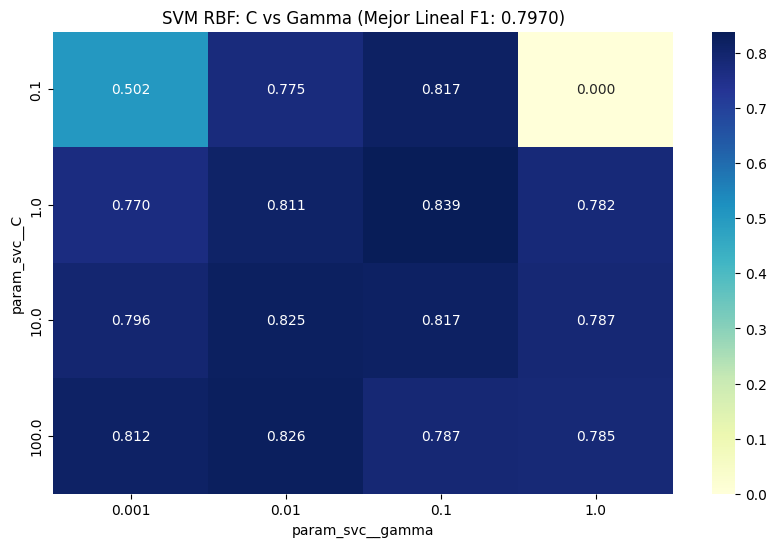

In [186]:
res_svm_wide = pd.DataFrame(grid_svm_wide.cv_results_)
pivot_svm_wide = res_svm_wide.pivot_table(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_svm_wide, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title(f'SVM RBF: C vs Gamma (Mejor Lineal F1: {grid_svm_linear.best_score_:.4f})')
plt.show()

El heatmap del HPO del kernel RBF revela una interacción crítica entre **C** (penalización) y **Gamma** (alcance del kernel):

- **Diagonal de rendimiento**: Se observa una franja de alto rendimiento que atraviesa el gráfico. Para valores bajos de `gamma` (0.001), el modelo necesita un `C` más alto (100) para compensar la simplicidad del kernel. Por el contrario, con un `gamma` más alto (0.1), un `C` moderado (1) es suficiente para alcanzar el máximo.
- **Zona de Underfitting (Esquina superior izquierda)**: Con `C=0.1` y `gamma=0.001`, el rendimiento es muy bajo (~0.502). El modelo es demasiado rígido y el kernel demasiado amplio, tratando de clasificar casi todo como la clase mayoritaria.
- **Zona de Overfitting (Esquina inferior derecha)**: Aunque no se desploma drásticamente en validación, valores de `gamma=1` tienden a crear fronteras de decisión demasiado complejas (islas alrededor de puntos).  
- **Colapso de modelo**: Para valores de gamma muy bajos (0.1) y gamma muy altos (1) directamente **F1 score = 0**, debido a que el modelo colapsa por empujar en direcciones opuestas. Es un modelo al que le exigimos ser simple pero con un una influencia muy local.
- **Punto Óptimo**: La combinación **C=1 y gamma=0.1** (F1=0.83386) representa el mejor equilibrio. Es una mejora significativa respecto al kernel lineal (0.7970), lo que demuestra que la frontera de decisión en este problema de depósitos bancarios es **claramente no lineal**.


### 4.3. Comparativa y Conclusiones

In [187]:
print(f"\n{'Modelo':<35} {'F1 CV':>10} {'Tiempo':>12}")
print("-" * 60)
print(f"{'Regresion Logistica (L1 HPO)':<35} {grid_l1_fine.best_score_:>10.4f} {t_l1_fine:>11.2f}s")
print(f"{'SVM Linear (HPO C=0.1)':<35} {grid_svm_linear.best_score_:>10.4f} {t_svm_linear:>11.2f}s")
print(f"{'SVM RBF (HPO C=1, gamma=0.1)':<35} {grid_svm_wide.best_score_:>10.4f} {t_svm_hpo_wide:>11.2f}s")


Modelo                                   F1 CV       Tiempo
------------------------------------------------------------
Regresion Logistica (L1 HPO)            0.7940        2.37s
SVM Linear (HPO C=0.1)                  0.7970       20.71s
SVM RBF (HPO C=1, gamma=0.1)            0.8386       27.90s


Tras optimizar ambos kernels, observamos resultados muy interesantes:

- **Kernel Lineal**: El mejor valor es **C=0.1**, con un **F1-score de 0.0.7970**.
- **Kernel RBF**: El mejor valor es **C=1.0 y $\gamma$=0.1**, alcanzando un **F1-score de 0.8386**.

**Análisis de los Hiperparámetros y Coste Computacional**:
1. **Desplazamiento de C**: El valor de $C$ óptimo aumenta al pasar del kernel lineal al RBF, permitiendo un ajuste más fino en dimensiones superiores.
2. **Rendimiento vs Tiempo**: El kernel RBF es el modelo más potente hasta ahora, pero con un **coste computacional notablemente superior**. Mientras que la Regresión Logística tarda ni dos segundos, la búsqueda de hiperparámetros para SVM ha requerido superar el minuto. Esta es una limitación intrínseca de las SVM ($O(n^2)$ a $O(n^3)$), lo que plantea un compromiso entre la ganancia en precisión (~4%) y la escalabilidad del modelo.

En conclusión, aunque el ajuste de hiperparámetros del SVM con kernel RBF es mucho más costoso en tiempo, se consigue un F1-score mucho más alto. Aun así, esto ocurre al entrenar varios modelos por utilizar HPO con grid search. Para el entrenamiento del modelo real no tardaría tanto al realizarse una única vez.

# 5. Resultados y Modelo Final

## 5.1. Selección del mejor modelo

Comparamos todos los modelos evaluados usando la **evaluación inner** 
(3-fold CV sobre train) con F1-score como métrica principal:

In [188]:
print(f"\n{'Modelo':<35} {'F1 CV (inner)':>15}")
print("-" * 52)
print(f"{'KNN (HPO, k=13)':<35} {grid_knn.best_score_:>15.4f}")
print(f"{'Árbol (HPO fino)':<35} {grid_tree_fine.best_score_:>15.4f}")
print(f"{'Regresion Logistica (L1 HPO)':<35} {grid_l1_fine.best_score_:>15.4f}")
print(f"{'SVM Linear (HPO C=0.1)':<35} {grid_svm_linear.best_score_:>15.4f}")
print(f"{'SVM RBF (HPO)':<35} {grid_svm_wide.best_score_:>15.4f}")


Modelo                                F1 CV (inner)
----------------------------------------------------
KNN (HPO, k=13)                              0.7897
Árbol (HPO fino)                             0.8169
Regresion Logistica (L1 HPO)                 0.7940
SVM Linear (HPO C=0.1)                       0.7970
SVM RBF (HPO)                                0.8386


El mejor modelo según la evaluación inner es el **SVM con kernel RBF** 
(F1=0.8386), seguido del árbol con HPO fino (F1=0.8169). 

El SVM RBF supera a todos los demás modelos con una diferencia notable 
(+0.020 respecto al árbol), lo que es consistente con lo esperado: 
el EDA mostró que el problema no es linealmente separable, y el kernel 
RBF es capaz de capturar fronteras de decisión no lineales de forma 
más flexible que los árboles.

**Seleccionamos el SVM RBF con HPO** como modelo final.

## 5.2. Estimación del rendimiento futuro (evaluación outer)

Evaluamos el modelo seleccionado sobre el **conjunto de test**, que no 
ha sido usado en ningún momento durante el entrenamiento ni la selección 
de modelos. Esta es una estimación honesta del rendimiento esperado en 
la competición.

In [189]:
from sklearn.metrics import (f1_score, confusion_matrix, 
                              classification_report, ConfusionMatrixDisplay)

Entrenamos el modelo seleccionado (HistGradientBoosting) sobre el conjunto de entrenamiento para validarlo contra el conjunto de test.

In [190]:
best_C_svm     = grid_svm_wide.best_params_["svc__C"]
best_gamma_svm = grid_svm_wide.best_params_["svc__gamma"]

modelo_final = Pipeline([
    ("preprocessor", preprocessor_final),
    ("svc", SVC(kernel="rbf", C=best_C_svm, gamma=best_gamma_svm,
                random_state=SEED))
])

modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)

f1_test  = f1_score(y_test, y_pred, pos_label="yes")
print(f"F1-score en test (outer): {f1_test:.4f}")
print(f"\nInforme de clasificación:")
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))

F1-score en test (outer): 0.8437

Informe de clasificación:
              precision    recall  f1-score   support

          no       0.88      0.81      0.85      1927
         yes       0.81      0.88      0.84      1740

    accuracy                           0.85      3667
   macro avg       0.85      0.85      0.85      3667
weighted avg       0.85      0.85      0.85      3667



Visualizamos la **Matriz de Confusión** para ver dónde está acertando nuestro modelo y dónde se está confundiendo, incluyendo el F1-Score para tener la visión global del rendimiento.

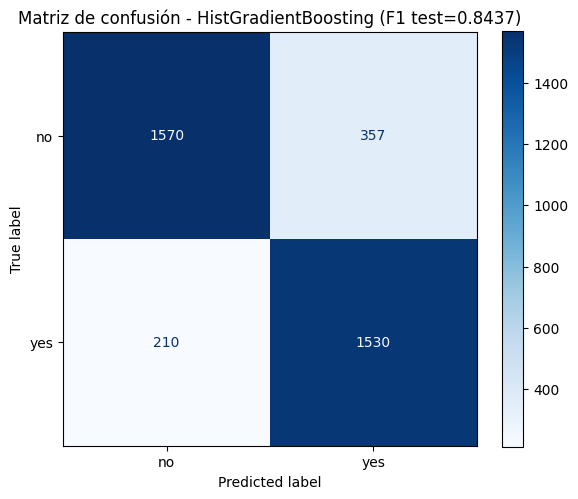

In [191]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["no", "yes"],
    cmap="Blues", ax=ax
)
ax.set_title(f"Matriz de confusión - HistGradientBoosting (F1 test={f1_test:.4f})")
plt.tight_layout()
plt.show()

Resultados de la Matriz de confusión:
- **Verdaderos NO**: 1570, Precision 0.88, Recall 0.81, Buena precisión pero peor Recall
- **Falsos NO**: 210
- **Verdaderos SI**: 1530, Pecision 0.81, Recall 0.88, Buen recall pero peor precision.
- **Falsos SI**: 357

Se obtiene un **accuracy = 0.85** y un **F1-score = 0.8437**, siendo valores mejores que los calculados cuando estabamos haciendo el HPO.

## 5.3. Entrenamiento del modelo final y guardado

A continuación, entrenaremos el modelo definitivo sobre **TODOS los datos** (uniendo los conjuntos de `train` y `test`) para maximizar la información disponible de cara a futuras predicciones. 

Para ello, creamos un `Pipeline` completo que integra la fase previa de transformación (`preprocessor_final`) y nuestro algoritmo **SVC** con los hiperparámetros óptimos encontrados.

In [192]:
modelo_final_completo = Pipeline([
    ("preprocessor", preprocessor_final),
    ("svc", SVC(kernel="rbf", C=best_C_svm, gamma=best_gamma_svm,
                random_state=SEED))
])

modelo_final_completo.fit(
    pd.concat([X_train, X_test]),
    pd.concat([y_train, y_test])
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('month_cyc', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transf

Para finalizar guardamos y exportamos el modelo resultante en el archivo `modelo_final.pkl`.

In [193]:
import cloudpickle

with open("modelo_final.pkl", "wb") as f:
    cloudpickle.dump(modelo_final_completo, f)
print("Modelo final guardado en 'modelo_final.pkl'")

Modelo final guardado en 'modelo_final.pkl'


Con la exportación del pipeline a `modelo_final.pkl`, concluimos la fase de entrenamiento y experimentación de este *notebook*. 


# 6. Elección Abierta: HistGradientBoostingClassifier

Como tarea de elección abierta, hemos seleccionado el **HistGradientBoostingClassifier**. Este modelo es una implementación de Gradient Boosting extremadamente eficiente. Utiliza un agrupamiento de las variables numéricas en bins, lo que reduce el coste computacional y permite manejar grandes volúmenes de datos de forma ágil.

Es un modelo muy potente para datos tabulares y, a diferencia de los SVM, no es estrictamente dependiente del escalado (aunque puede integrarse perfectamente en nuestro pipeline actual). Además, realizaremos una **validación cruzada anidada** para asegurar que la optimización de hiperparámetros no sesga nuestra estimación del rendimiento.


Pipeline para HGB, reusando preprocesador final:

In [194]:
hgb_pipe = Pipeline([
    ('preprocessor', preprocessor_final),
    ('classifier', HistGradientBoostingClassifier(random_state=SEED))
])

Haremos **ajuste de hiperparámetros** de `learning_rate`, `max_depth`y `min_saamples_leaf`

In [195]:
param_grid_hgb = {
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [5, 10, 15, 20],
    'classifier__min_samples_leaf': [10, 20, 50]
}


Bucles de HPO con validación cruzada anidada

In [196]:

# 1. Bucle interno (HPO)
cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
grid_hgb = GridSearchCV(hgb_pipe, param_grid_hgb, cv=cv_inner, scoring=f1, n_jobs=-1)

# 2. Bucle externo (Nested CV - Estimación insesgada)
cv_outer = StratifiedKFold(n_splits=3, shuffle=True, random_state=100498961) # usamos el NIA de Iker, porque es bueno que sean diferentes.
nested_scores_hgb = cross_val_score(grid_hgb, X_train, y_train, cv=cv_outer, scoring=f1, n_jobs=-1)

print(f'Rendimiento estimado del HGB (Nested CV F1): {nested_scores_hgb.mean():.4f} +/- {nested_scores_hgb.std():.4f}')


Rendimiento estimado del HGB (Nested CV F1): 0.8589 +/- 0.0066


> Importante **SEED diferente**: buena práctica para más aleatorización, es como volverlo a barajar, de manera diferente.

Ahora ajuste sobre todo train:

In [197]:
grid_hgb.fit(X_train, y_train)

print(f'Mejores parámetros encontrados: {grid_hgb.best_params_}')
print(f'Mejor F1 (CV Interno): {grid_hgb.best_score_:.4f}')


Mejores parámetros encontrados: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 15, 'classifier__min_samples_leaf': 10}
Mejor F1 (CV Interno): 0.8621


Vemos que se obtiene con HPO un **F1-score = 0.8621**, más alto que con SVM (incluso con la evaluación sobre test). Es mayor al del rendimiento esperado del HGB calculado antes (0.8561), lo cual implica un ligero sesgo optimista (optimistic bias) en la evaluación interna, siendo el resultado del Nested CV (0.8561) una estimación más realista de cómo generalizará el modelo en datos nuevos

## 6.1. Efecto de hiperparámetros

Visualizamos mediante un Heatmap la interacción entre la profundidad máxima y la tasa de aprendizaje, manteniendo fijo el valor óptimo de `min_samples_leaf` para esta visualización.


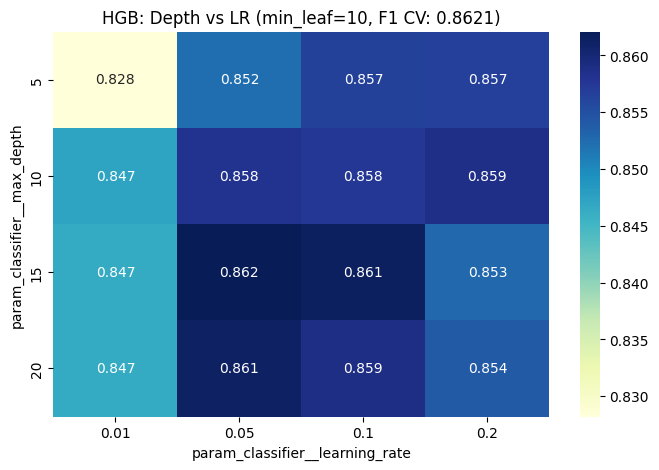

In [198]:
res_hgb = pd.DataFrame(grid_hgb.cv_results_)
# Filtramos por el mejor min_samples_leaf para el heatmap
best_msl = grid_hgb.best_params_['classifier__min_samples_leaf']
res_hgb_plot = res_hgb[res_hgb['param_classifier__min_samples_leaf'] == best_msl]

pivot_hgb = res_hgb_plot.pivot_table(index='param_classifier__max_depth', 
                                     columns='param_classifier__learning_rate', 
                                     values='mean_test_score')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_hgb, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title(f'HGB: Depth vs LR (min_leaf={best_msl}, F1 CV: {grid_hgb.best_score_:.4f})')
plt.show()

Se ve claramente como a valores mayores de profundidad cercanos a 15 el F1-score incrementa, dejando de hacerlo si se sobrepasa (*overfitting*). Además, para valores medios para el learning rate tiene mejores resultados. Se consigue maxiizar en **profundidad = 15** y **learning rate = 0,5**.

## 5.2. Análisis de Importancia de Variables (Permutation Importance)

Para dotar de interpretabilidad al modelo, utilizamos `permutation_importance`. Este método evalúa cómo cae el rendimiento del modelo al permutar aleatoriamente cada variable, revelando cuáles son las que más información aportan para la clasificación.


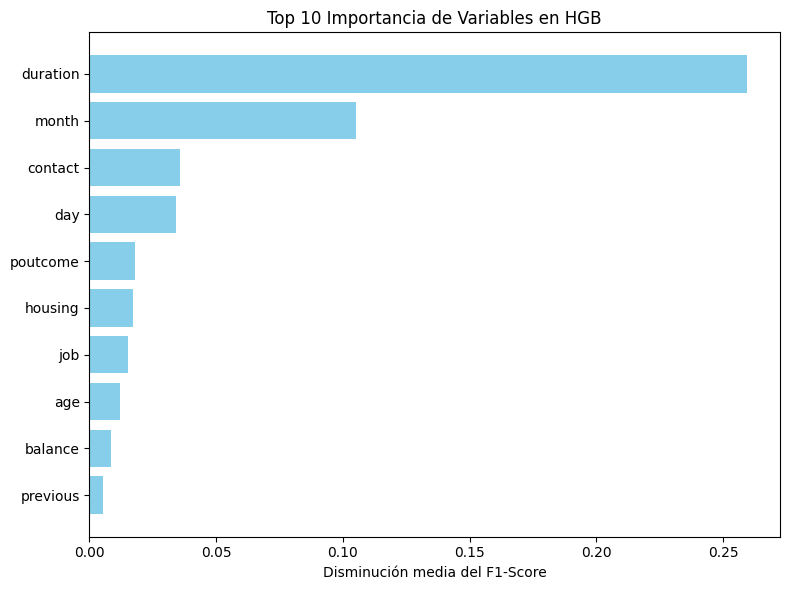

In [199]:
result_hgb = permutation_importance(grid_hgb.best_estimator_, X_train, y_train, 
                                   scoring=f1, n_repeats=10, random_state=SEED, n_jobs=-1)

sorted_idx = result_hgb.importances_mean.argsort()[-10:]
importances = result_hgb.importances_mean[sorted_idx]
features = X_train.columns[sorted_idx]

plt.figure(figsize=(8, 6))
plt.barh(range(len(sorted_idx)), importances, align='center', color='skyblue')
plt.yticks(range(len(sorted_idx)), features)
plt.xlabel('Disminución media del F1-Score')
plt.title('Top 10 Importancia de Variables en HGB')
plt.tight_layout()
plt.show()


Se ve de esta manera que las variables que más información aportan para la clasificación son `duration` (cosa que ya sabiamos), así como `month`(sabíamos para algunos meses como marzo) o `contact` (que también sabemos que es bastante discrimatoria, especialmente con valores *unknown*).